# CS781 Phase 2. Prefix language model with LoRMA+ and a learned CRF

I froze the Phase 1 prefix model and adapted its 16 shared blocks with LoRMA+. Both branches receive the same 1,024-token window. The bidirectional prefix supplies context and the continuation position for each token predicts its BIO tag and character boundaries. A learned CRF decodes the document, and the span postprocessor trims edge whitespace.

| Run | Best epoch | Validation strict macro F1 | CodaBench strict macro F1 | Submission ID |
| --- | ---: | ---: | ---: | ---: |
| `prefix_ner_lorma_crf_001_fresh` | 22 | 0.428613 | 0.3794 | 976545 |

Early stopping ended training at epoch 30. The export used the best validation checkpoint at epoch 22.


## 1. Inputs and environment

1. Start a Kaggle notebook with two T4 GPUs. Keep Kaggle's PyTorch installation.
2. Attach `prep_002_mixed16k` with `tokenizer_state.pkl` and `cache_manifest.json`, and the original
   [Phase 1 run](../phase1/phase1_prefix_training.ipynb) `prefix_001_mixed217m` with `best_model.pt` and its source metadata.
   Set `PREP_INPUT` and `PREFIX_INPUT` when automatic discovery is ambiguous.
3. Attach `Phase_2_LNER` or `phase2_lner_data.zip` through `PHASE2_INPUT`, or enable Internet
   and provide the Kaggle secret `HF_TOKEN` for the pinned dataset download.
4. The Phase 1 input can be an extracted run, a ZIP, or the split `manifest.json` with all companion parts. The saved execution resumed the same NER run. Set `RESUME_INPUT` only to resume this NER run from its saved files.


In [1]:
%pip install -q huggingface_hub matplotlib


Note: you may need to restart the kernel to use updated packages.


In [2]:
import gc
import hashlib
import json
import math
import pickle
import random
import shutil
import sys
import time
from dataclasses import asdict
from pathlib import Path

import numpy as np
import torch

PREPARATION_ID = "prep_002_mixed16k"
PHASE1_RUN_ID = "prefix_001_mixed217m"
RUN_ID = "prefix_ner_lorma_crf_001_fresh"

# None finds the matching Kaggle input automatically. Use exact paths if several matches exist.
PREP_INPUT = None
PREFIX_INPUT = None  # Extracted run, exact best_model.pt, or Phase 1 backup ZIP
PHASE2_INPUT = None          # Optional dataset folder or phase2_lner_data.zip
RESUME_INPUT = None          # THIS run's NER backup ZIP or extracted NER run folder

HF_DATASET_REVISION = "89edba6a44d6bb9593fd13b6895b5cd3b06eb82e"
ROOT = Path("/kaggle/working/cs781_phase2")
SRC = Path("/kaggle/working/cs781_phase2_prefix_lorma_crf_src")
RUN_DIR = ROOT / "runs" / RUN_ID
ROOT.mkdir(parents=True, exist_ok=True)
SRC.mkdir(parents=True, exist_ok=True)
RUN_DIR.mkdir(parents=True, exist_ok=True)

WINDOW_TOKENS = 1024
WINDOW_OVERLAP = 256
VALIDATION_FRACTION = 0.20
SETTINGS = {
    "seed": 42,
    "epochs": 50,
    "minimum_epochs": 10,
    "patience": 8,
    "early_stop_min_delta": 0.001,
    "microbatch_size": 4,       # total across both GPUs
    "accumulation_steps": 4,   # effective batch 16 windows
    "prediction_batch_size": 4,
    "adapter_variant": "lorma_plus",
    "lorma_rank": 32,
    "lorma_alpha": 64,
    "lorma_dropout": 0.05,
    "lorma_lr": 1e-4,
    "tag_head_lr": 2e-4,
    "boundary_head_lr": 5e-5,
    "crf_lr": 1e-3,
    "adapter_weight_decay": 0.01,
    "head_weight_decay": 0.01,
    "head_dropout": 0.10,
    "tag_label_smoothing": 0.0,
    "aux_tag_loss_weight": 0.25,
    "warmup_epochs": 1,
    "lr_factor": 0.5,
    "lr_patience": 3,          # number of non-improving validation checks
    "minimum_lr_fraction": 0.20,
    "gradient_clip": 1.0,
    "boundary_loss_weight": 0.5,
    "class_weighting": "balanced_bio",
    "outside_tag_weight": 0.25,
    "decode_mode": "crf",
    "trim_span_whitespace": True,
    "gradient_checkpointing": True,
    "save_every_minutes": 5,
    "log_every": 10,
    "max_run_hours": 9.0,
    "minimum_free_gb": 1.0,
}
GENERATE_TEST_PREDICTIONS = True
MAKE_RESUME_BACKUP = True
REFERENCE_DECODER_VALIDATION_F1 = 0.44049594135847553
REFERENCE_ENCDEC_VALIDATION_F1 = 0.41560609203701304

if not torch.cuda.is_available() or torch.cuda.device_count() != 2:
    raise RuntimeError("Select GPU T4 x2 in Kaggle before running this notebook")
device = torch.device("cuda:0")
random.seed(SETTINGS["seed"])
np.random.seed(SETTINGS["seed"])
torch.manual_seed(SETTINGS["seed"])
torch.cuda.manual_seed_all(SETTINGS["seed"])
print("PyTorch:", torch.__version__)
for i in range(torch.cuda.device_count()):
    p = torch.cuda.get_device_properties(i)
    print(f"GPU {i}: {p.name}, {p.total_memory / 2**30:.1f} GiB")
print("Effective batch:", SETTINGS["microbatch_size"] * SETTINGS["accumulation_steps"], "windows")
print("Run folder:", RUN_DIR)


PyTorch: 2.11.0+cu128
GPU 0: Tesla T4, 14.6 GiB
GPU 1: Tesla T4, 14.6 GiB
Effective batch: 16 windows
Run folder: /kaggle/working/cs781_phase2/runs/prefix_ner_lorma_crf_001_fresh


## 2. Model and data implementation

The cells below write the matching Phase 1 backbone and tokenizer, the offset and window
helpers, the NER model and trainer, and the course evaluator into the working directory.
The preparation and checkpoint checks use the saved source hashes.


In [3]:
%%writefile /kaggle/working/cs781_phase2_prefix_lorma_crf_src/phase1_utils.py
"""Small file and JSON helpers used by the Phase-1 notebooks."""
import hashlib
import json
import os
import pickle
import zipfile
from pathlib import Path


def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(8 * 1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def text_hash(text):
    return hashlib.sha256(text.encode("utf-8")).hexdigest()


def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def atomic_json(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8")
    os.replace(temporary, path)


def atomic_pickle(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    with open(temporary, "wb") as file:
        pickle.dump(value, file, protocol=pickle.HIGHEST_PROTOCOL)
        file.flush()
        os.fsync(file.fileno())
    os.replace(temporary, path)


def checked_json(path, value):
    path = Path(path)
    if path.exists() and read_json(path) != value:
        raise ValueError(f"Saved settings differ: {path}. Use a new experiment ID.")
    atomic_json(path, value)


def write_source(path, content):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    raw = content.encode("utf-8") if isinstance(content, str) else content
    if path.exists():
        if path.read_bytes() != raw:
            raise ValueError(f"Saved source differs: {path}. Keep its code or use a new experiment ID.")
        return
    path.write_bytes(raw)


def make_bundle(folder, output_path, archive_root):
    folder, output_path, archive_root = Path(folder), Path(output_path), Path(archive_root)
    temporary = output_path.with_suffix(".zip.tmp")
    with zipfile.ZipFile(temporary, "w", compression=zipfile.ZIP_STORED) as archive:
        for path in sorted(folder.rglob("*")):
            if path.is_file() and "__pycache__" not in path.parts and not path.name.endswith(".tmp"):
                archive.write(path, path.relative_to(archive_root))
    os.replace(temporary, output_path)
    return output_path



def split_bundle(zip_path, part_bytes=256 * 2**20, keep_zip=False):
    """Create checked .bin parts for Kaggle's output-file download buttons."""
    import shutil
    zip_path = Path(zip_path)
    if part_bytes <= 0:
        raise ValueError("Part size must be positive")
    zip_hash = sha256_file(zip_path)
    folder = zip_path.parent / (zip_path.stem + "_parts_" + zip_hash[:12])
    folder.mkdir(parents=True, exist_ok=True)
    manifest_path = folder / "manifest.json"
    if manifest_path.exists():
        old = read_json(manifest_path)
        if (old.get("format") == "cs781_split_zip_v1"
                and old["zip_sha256"] == zip_hash and old["part_bytes"] == part_bytes
                and bool(old["parts"])
                and sum(row["size_bytes"] for row in old["parts"]) == zip_path.stat().st_size
                and all((folder / row["name"]).is_file()
                        and (folder / row["name"]).stat().st_size == row["size_bytes"]
                        and sha256_file(folder / row["name"]) == row["sha256"]
                        for row in old["parts"])):
            if not keep_zip:
                zip_path.unlink()
            return manifest_path
    if shutil.disk_usage(folder).free < zip_path.stat().st_size + 512 * 2**20:
        raise RuntimeError("Not enough disk to split the ZIP safely. Preserve the run folder in saved outputs.")
    rows = []
    whole = hashlib.sha256()
    with open(zip_path, "rb") as source:
        number = 1
        while True:
            first = source.read(min(8 * 2**20, part_bytes))
            if not first:
                break
            part = folder / f"backup.part{number:03d}.bin"
            temporary = part.with_suffix(part.suffix + ".tmp")
            digest = hashlib.sha256()
            written = 0
            with open(temporary, "wb") as target:
                chunk = first
                while chunk:
                    target.write(chunk)
                    digest.update(chunk)
                    whole.update(chunk)
                    written += len(chunk)
                    chunk = source.read(min(8 * 2**20, part_bytes - written)) if written < part_bytes else b""
                target.flush()
                os.fsync(target.fileno())
            os.replace(temporary, part)
            rows.append({"name": part.name, "size_bytes": written, "sha256": digest.hexdigest()})
            number += 1
    if whole.hexdigest() != zip_hash:
        raise ValueError("ZIP changed while splitting; keep the ZIP and try again after training stops")
    atomic_json(manifest_path, {"format": "cs781_split_zip_v1", "zip_name": zip_path.name,
        "zip_size_bytes": zip_path.stat().st_size, "zip_sha256": zip_hash,
        "part_bytes": part_bytes, "parts": rows})
    if not keep_zip:
        zip_path.unlink()  # the same backup bytes remain in the checked parts
    return manifest_path


def reassemble_bundle(manifest_path, output_folder):
    """Restore the original ZIP with bounded RAM and verify every part."""
    manifest_path = Path(manifest_path)
    manifest = read_json(manifest_path)
    if manifest.get("format") != "cs781_split_zip_v1":
        raise ValueError("Unknown split-backup format")
    name = manifest["zip_name"]
    if Path(name).name != name:
        raise ValueError("ZIP name must be a plain filename")
    output_folder = Path(output_folder)
    output_folder.mkdir(parents=True, exist_ok=True)
    output = output_folder / name
    if output.exists():
        if output.stat().st_size == manifest["zip_size_bytes"] and sha256_file(output) == manifest["zip_sha256"]:
            return output
        raise ValueError(f"A different file already exists: {output}")
    temporary = output.with_suffix(output.suffix + ".tmp")
    whole = hashlib.sha256()
    total = 0
    try:
        with open(temporary, "wb") as target:
            for row in manifest["parts"]:
                if Path(row["name"]).name != row["name"]:
                    raise ValueError("Part name must be a plain filename")
                part = manifest_path.parent / row["name"]
                if part.stat().st_size != row["size_bytes"]:
                    raise ValueError(f"Part size differs: {part}")
                digest = hashlib.sha256()
                with open(part, "rb") as source:
                    for chunk in iter(lambda: source.read(8 * 2**20), b""):
                        target.write(chunk)
                        whole.update(chunk)
                        digest.update(chunk)
                        total += len(chunk)
                if digest.hexdigest() != row["sha256"]:
                    raise ValueError(f"Part checksum differs: {part}")
            target.flush()
            os.fsync(target.fileno())
        if total != manifest["zip_size_bytes"] or whole.hexdigest() != manifest["zip_sha256"]:
            raise ValueError("Reassembled ZIP checksum differs")
        os.replace(temporary, output)
    except Exception:
        temporary.unlink(missing_ok=True)
        raise
    return output


Overwriting /kaggle/working/cs781_phase2_prefix_lorma_crf_src/phase1_utils.py


In [4]:
%%writefile /kaggle/working/cs781_phase2_prefix_lorma_crf_src/a1_tokenizer.py
"""The assignment byte-BPE algorithm, with checkpoints between merges.

Pair counting, lexicographic tie breaking, non-overlapping replacements and
merge-order encoding are unchanged from the completed Phase-1/A3 tokenizer.
"""
import pickle
import re
import time
from collections import Counter
from pathlib import Path
from phase1_utils import atomic_pickle, sha256_file, text_hash


class A1BPETokenizer:
    def __init__(self):
        specials = ["<pad>", "<unk>", "<s>", "</s>"]
        self.vocab = [s.encode("utf-8") for s in specials]
        self.vocab += [bytes([b]) for b in range(256)]
        self.boundary_id = len(self.vocab)
        self.vocab.append(b"")
        self.names = [s.encode("utf-8") for s in specials]
        self.names += [bytes([b]) for b in range(256)]
        self.names.append(b"</w>")
        self.merges = {}
        self.vocab_size = len(self.vocab)

    def fit(self, text, vocab_size, checkpoint_path=None, checkpoint_merges=100,
            stop_after_merges=None):
        if vocab_size < 261:
            raise ValueError("Vocabulary must accommodate bytes and reserved tokens")
        signature = {"text_sha256": text_hash(text), "vocab_size": vocab_size,
                     "algorithm_source_sha256": sha256_file(__file__)}
        checkpoint_path = Path(checkpoint_path) if checkpoint_path is not None else None
        elapsed_before = 0.0
        if checkpoint_path is not None and checkpoint_path.exists():
            with open(checkpoint_path, "rb") as file:
                saved = pickle.load(file)
            if saved["signature"] != signature:
                raise ValueError("BPE checkpoint settings or source differ")
            self.__dict__.update(saved["tokenizer_state"])
            words = saved["words"]
            elapsed_before = saved["elapsed_seconds"]
            print("Resuming BPE vocabulary:", self.vocab_size, flush=True)
        else:
            if self.merges:
                raise ValueError("Use a fresh tokenizer or its saved fitting checkpoint")
            words = Counter(tuple(b + 4 for b in piece.encode("utf-8")) + (self.boundary_id,)
                            for piece in re.findall(r"\S+|\s+", text))
        started = time.monotonic()
        last_saved = started
        merges_this_call = 0
        commit_in_progress = False

        def snapshot():
            if checkpoint_path is not None:
                atomic_pickle(checkpoint_path, {"signature": signature,
                    "tokenizer_state": self.__dict__, "words": words,
                    "elapsed_seconds": elapsed_before + time.monotonic() - started})

        try:
            while len(self.vocab) < vocab_size:
                pair_counts = Counter()
                for symbols, frequency in words.items():
                    for pair in zip(symbols, symbols[1:]):
                        pair_counts[pair] += frequency
                if not pair_counts:
                    break
                pair = min(pair_counts, key=lambda p: (-pair_counts[p], self.names[p[0]], self.names[p[1]]))
                if pair_counts[pair] < 2:
                    break
                new_id = len(self.vocab)
                updated = Counter()
                for symbols, frequency in words.items():
                    result = []
                    j = 0
                    while j < len(symbols):
                        if j + 1 < len(symbols) and symbols[j:j + 2] == pair:
                            result.append(new_id)
                            j += 2
                        else:
                            result.append(symbols[j])
                            j += 1
                    updated[tuple(result)] += frequency
                # Commit the whole merge only after every word has been replaced.
                commit_in_progress = True
                self.vocab.append(self.vocab[pair[0]] + self.vocab[pair[1]])
                self.names.append(self.names[pair[0]] + self.names[pair[1]])
                self.merges[pair] = new_id
                self.vocab_size = len(self.vocab)
                words = updated
                commit_in_progress = False
                merges_this_call += 1
                if len(self.merges) % checkpoint_merges == 0 or time.monotonic() - last_saved >= 60:
                    snapshot()
                    print(f"BPE vocabulary {self.vocab_size:,}/{vocab_size:,} | "
                          f"elapsed {(elapsed_before + time.monotonic() - started)/60:.1f} min", flush=True)
                    last_saved = time.monotonic()
                if stop_after_merges is not None and merges_this_call >= stop_after_merges:
                    break
        finally:
            if not commit_in_progress:
                snapshot()
        return self

    def encode(self, text):
        result = []
        for piece in re.findall(r"\S+|\s+", text):
            symbols = [b + 4 for b in piece.encode("utf-8")] + [self.boundary_id]
            while len(symbols) > 1:
                candidates = [(self.merges[(a, b)], (a, b))
                              for a, b in zip(symbols, symbols[1:]) if (a, b) in self.merges]
                if not candidates:
                    break
                new_id, pair = min(candidates)
                merged = []
                j = 0
                while j < len(symbols):
                    if j + 1 < len(symbols) and (symbols[j], symbols[j + 1]) == pair:
                        merged.append(new_id)
                        j += 2
                    else:
                        merged.append(symbols[j])
                        j += 1
                symbols = merged
            result.extend(symbols)
        return result

    def decode(self, ids):
        return b"".join(self.vocab[i] for i in ids).decode("utf-8")


Overwriting /kaggle/working/cs781_phase2_prefix_lorma_crf_src/a1_tokenizer.py


In [5]:
%%writefile /kaggle/working/cs781_phase2_prefix_lorma_crf_src/architecture_models.py
"""Three from-scratch Phase 1 Transformers; course blocks with cited extensions.

SDPA Boolean masks use True for ALLOWED connections. All blocks are pre-norm.
Training uses full teacher-forced sequences. KV caches are inference-only.
"""
import math
from dataclasses import dataclass
import torch
import torch.nn as nn
import torch.nn.functional as F


@dataclass
class ModelConfig:
    architecture: str = "encoder_decoder"
    vocab_size: int = 16000
    d_model: int = 1024
    n_heads: int = 16
    n_layers: int = 16
    encoder_layers: int = 8
    decoder_layers: int = 6
    n_kv_heads: int = 4
    d_ff: int = 4096
    max_seq_len: int = 2560
    dropout: float = 0.1
    window_size: int = 512
    query_chunk_size: int = 128


def configuration(architecture):
    if architecture not in ("encoder_decoder", "prefix", "efficient"):
        raise ValueError("Unknown architecture")
    return ModelConfig(architecture=architecture, d_ff=4864 if architecture == "efficient" else 4096)


def positions(max_len, width):
    p = torch.arange(max_len).unsqueeze(1).float()
    frequency = torch.exp(torch.arange(0, width, 2).float() * (-math.log(10000.0) / width))
    result = torch.zeros(max_len, width)
    result[:, 0::2] = torch.sin(p * frequency)
    result[:, 1::2] = torch.cos(p * frequency)
    return result


def valid_keys(lengths, width):
    return torch.arange(width, device=lengths.device)[None, :] < lengths[:, None]


class Attention(nn.Module):
    def __init__(self, cfg, kv_heads=None):
        super().__init__()
        self.heads = cfg.n_heads
        self.kv_heads = cfg.n_heads if kv_heads is None else kv_heads
        assert cfg.d_model % self.heads == 0 and self.heads % self.kv_heads == 0
        self.head_dim = cfg.d_model // self.heads
        self.q_proj = nn.Linear(cfg.d_model, cfg.d_model, bias=False)
        self.k_proj = nn.Linear(cfg.d_model, self.kv_heads * self.head_dim, bias=False)
        self.v_proj = nn.Linear(cfg.d_model, self.kv_heads * self.head_dim, bias=False)
        self.out_proj = nn.Linear(cfg.d_model, cfg.d_model, bias=False)
        self.dropout = cfg.dropout
        self.resid_dropout = nn.Dropout(cfg.dropout)

    def query(self, x):
        b, t, _ = x.shape
        return self.q_proj(x).view(b, t, self.heads, self.head_dim).transpose(1, 2)

    def keys_values(self, x):
        b, t, _ = x.shape
        k = self.k_proj(x).view(b, t, self.kv_heads, self.head_dim).transpose(1, 2)
        v = self.v_proj(x).view(b, t, self.kv_heads, self.head_dim).transpose(1, 2)
        return k, v

    def attend(self, q, k, v, allowed=None, causal=False):
        # A3 Q2: repeat each KV head for its group of query heads.
        if self.kv_heads != self.heads:
            repeats = self.heads // self.kv_heads
            k, v = k.repeat_interleave(repeats, dim=1), v.repeat_interleave(repeats, dim=1)
        out = F.scaled_dot_product_attention(q, k, v, attn_mask=allowed, is_causal=causal,
            dropout_p=self.dropout if self.training else 0.0, scale=1 / math.sqrt(self.head_dim))
        b, _, t, _ = out.shape
        out = out.transpose(1, 2).contiguous().view(b, t, -1)
        return self.resid_dropout(self.out_proj(out))

    def forward(self, x, memory=None, allowed=None, causal=False):
        k, v = self.keys_values(x if memory is None else memory)
        return self.attend(self.query(x), k, v, allowed, causal)

    def local(self, x, window, chunk, lengths=None):
        # Query tiles see only nearby keys. No full T-by-T score matrix.
        q = self.query(x)
        k, v = self.keys_values(x)
        t = x.shape[1]
        pieces = []
        for start in range(0, t, chunk):
            stop = min(t, start + chunk)
            first = max(0, start - window + 1)
            qi = torch.arange(start, stop, device=x.device)
            ki = torch.arange(first, stop, device=x.device)
            allowed = (ki[None, :] <= qi[:, None]) & (ki[None, :] > qi[:, None] - window)
            allowed = allowed[None, None, :, :]
            if lengths is not None:
                allowed = allowed & (ki[None, :] < lengths[:, None])[:, None, None, :]
            pieces.append(self.attend(q[:, :, start:stop], k[:, :, first:stop], v[:, :, first:stop], allowed))
        return torch.cat(pieces, dim=1)


class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(cfg.d_model, cfg.d_ff), nn.GELU(),
                                 nn.Linear(cfg.d_ff, cfg.d_model), nn.Dropout(cfg.dropout))

    def forward(self, x):
        return self.net(x)


class EncoderBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(cfg.d_model), nn.LayerNorm(cfg.d_model)
        self.attn, self.ffn = Attention(cfg), FeedForward(cfg)

    def forward(self, x, allowed):
        x = x + self.attn(self.ln1(x), allowed=allowed)
        return x + self.ffn(self.ln2(x))


class DecoderBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.ln1, self.ln2, self.ln3 = (nn.LayerNorm(cfg.d_model) for _ in range(3))
        self.self_attn, self.cross_attn, self.ffn = Attention(cfg), Attention(cfg), FeedForward(cfg)

    def forward(self, x, memory, allowed):
        x = x + self.self_attn(self.ln1(x), causal=True)
        x = x + self.cross_attn(self.ln2(x), memory=memory, allowed=allowed)
        return x + self.ffn(self.ln3(x))


class PrefixBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(cfg.d_model), nn.LayerNorm(cfg.d_model)
        self.attn, self.ffn = Attention(cfg), FeedForward(cfg)

    def forward(self, prompt, decoder, prefix_allowed):
        # The prompt cannot see decoder tokens; decoder queries see both parts.
        p = self.ln1(prompt)
        d = self.ln1(decoder)
        pk, pv = self.attn.keys_values(p)
        dk, dv = self.attn.keys_values(d)
        prompt = prompt + self.attn.attend(self.attn.query(p), pk, pv, prefix_allowed)
        t = decoder.shape[1]
        triangular = torch.ones(t, t, dtype=torch.bool, device=decoder.device).tril()
        allowed = torch.cat([prefix_allowed.expand(-1, -1, t, -1),
                             triangular[None, None].expand(decoder.shape[0], 1, -1, -1)], dim=-1)
        decoder = decoder + self.attn.attend(self.attn.query(d), torch.cat([pk, dk], dim=2),
                                            torch.cat([pv, dv], dim=2), allowed)
        return prompt + self.ffn(self.ln2(prompt)), decoder + self.ffn(self.ln2(decoder))


class EfficientBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(cfg.d_model), nn.LayerNorm(cfg.d_model)
        self.attn, self.ffn = Attention(cfg, cfg.n_kv_heads), FeedForward(cfg)
        self.window, self.chunk = cfg.window_size, cfg.query_chunk_size

    def forward(self, x, lengths=None):
        x = x + self.attn.local(self.ln1(x), self.window, self.chunk, lengths)
        return x + self.ffn(self.ln2(x))


class BaseModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.register_buffer("pos_emb", positions(cfg.max_seq_len, cfg.d_model), persistent=False)
        self.head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight

    def initialize(self):
        for p in self.parameters():
            if p.ndim > 1:
                nn.init.xavier_uniform_(p)
        for m in self.modules():
            if isinstance(m, nn.Linear) and m.bias is not None:
                nn.init.zeros_(m.bias)

    def embed(self, ids, offset=None, role=None):
        t = ids.shape[1]
        p = torch.arange(t, device=ids.device)[None, :]
        if offset is not None:
            p = p + offset[:, None]
        x = self.tok_emb(ids) * math.sqrt(self.cfg.d_model) + self.pos_emb[p]
        if role is not None:
            x = x + self.segment_emb.weight[role]
        return x


class EncoderDecoderLM(BaseModel):
    def __init__(self, cfg):
        super().__init__(cfg)
        self.encoder = nn.ModuleList([EncoderBlock(cfg) for _ in range(cfg.encoder_layers)])
        self.decoder = nn.ModuleList([DecoderBlock(cfg) for _ in range(cfg.decoder_layers)])
        self.encoder_norm, self.decoder_norm = nn.LayerNorm(cfg.d_model), nn.LayerNorm(cfg.d_model)
        self.initialize()

    def encode(self, prompt, lengths):
        allowed = valid_keys(lengths, prompt.shape[1])[:, None, None, :]
        x = self.embed(prompt)
        for block in self.encoder:
            x = block(x, allowed)
        return self.encoder_norm(x), allowed

    def forward(self, prompt, decoder_ids, lengths=None):
        if prompt.shape[1] + decoder_ids.shape[1] > self.cfg.max_seq_len:
            raise ValueError("Prompt plus decoder exceeds context budget")
        if lengths is None:
            lengths = torch.full((prompt.shape[0],), prompt.shape[1], device=prompt.device, dtype=torch.long)
        memory, allowed = self.encode(prompt, lengths)
        x = self.embed(decoder_ids)
        for block in self.decoder:
            x = block(x, memory, allowed)
        return self.head(self.decoder_norm(x))

    def start_generation(self, prompt, lengths):
        memory, allowed = self.encode(prompt, lengths)
        layers = []
        for block in self.decoder:
            k, v = block.cross_attn.keys_values(memory)
            layers.append({"cross_k": k, "cross_v": v,
                           "k": k[:, :, :0], "v": v[:, :, :0]})
        cache = {"layers": layers, "allowed": allowed, "lengths": lengths,
                 "decoder_position": 0, "next_positions": lengths.clone()}
        bos = torch.full((prompt.shape[0], 1), 2, dtype=torch.long, device=prompt.device)
        return self.generation_step(bos, cache)

    def generation_step(self, ids, cache):
        position = cache["decoder_position"]
        x = self.embed(ids, offset=torch.full_like(cache["lengths"], position))
        for block, layer in zip(self.decoder, cache["layers"]):
            h = block.ln1(x)
            k, v = block.self_attn.keys_values(h)
            layer["k"], layer["v"] = torch.cat([layer["k"], k], dim=2), torch.cat([layer["v"], v], dim=2)
            # One new query may see all cached decoder keys, including itself.
            x = x + block.self_attn.attend(block.self_attn.query(h), layer["k"], layer["v"])
            x = x + block.cross_attn.attend(block.cross_attn.query(block.ln2(x)),
                                          layer["cross_k"], layer["cross_v"], cache["allowed"])
            x = x + block.ffn(block.ln3(x))
        cache["decoder_position"] += 1
        cache["next_positions"] = cache["lengths"] + cache["decoder_position"]
        return self.head(self.decoder_norm(x))[:, -1], cache


class PrefixLM(BaseModel):
    def __init__(self, cfg):
        super().__init__(cfg)
        self.segment_emb = nn.Embedding(2, cfg.d_model)
        self.blocks = nn.ModuleList([PrefixBlock(cfg) for _ in range(cfg.n_layers)])
        self.final_norm = nn.LayerNorm(cfg.d_model)
        self.initialize()

    def forward(self, prompt, decoder_ids, lengths=None):
        if prompt.shape[1] + decoder_ids.shape[1] > self.cfg.max_seq_len:
            raise ValueError("Prompt plus decoder exceeds context budget")
        if lengths is None:
            lengths = torch.full((prompt.shape[0],), prompt.shape[1], device=prompt.device, dtype=torch.long)
        allowed = valid_keys(lengths, prompt.shape[1])[:, None, None, :]
        p, d = self.embed(prompt, role=0), self.embed(decoder_ids, offset=lengths, role=1)
        for block in self.blocks:
            p, d = block(p, d, allowed)
        return self.head(self.final_norm(d))

    def start_generation(self, prompt, lengths):
        allowed = valid_keys(lengths, prompt.shape[1])[:, None, None, :]
        x = self.embed(prompt, role=0)
        layers = []
        for block in self.blocks:
            h = block.ln1(x)
            k, v = block.attn.keys_values(h)
            layers.append({"prefix_k": k, "prefix_v": v, "k": k[:, :, :0], "v": v[:, :, :0]})
            x = x + block.attn.attend(block.attn.query(h), k, v, allowed)
            x = x + block.ffn(block.ln2(x))
        cache = {"layers": layers, "allowed": allowed, "lengths": lengths,
                 "decoder_position": 0, "next_positions": lengths.clone()}
        bos = torch.full((prompt.shape[0], 1), 2, dtype=torch.long, device=prompt.device)
        return self.generation_step(bos, cache)

    def generation_step(self, ids, cache):
        x = self.embed(ids, offset=cache["next_positions"], role=1)
        for block, layer in zip(self.blocks, cache["layers"]):
            h = block.ln1(x)
            k, v = block.attn.keys_values(h)
            layer["k"], layer["v"] = torch.cat([layer["k"], k], dim=2), torch.cat([layer["v"], v], dim=2)
            allowed = torch.cat([cache["allowed"],
                torch.ones((ids.shape[0], 1, 1, layer["k"].shape[2]), device=ids.device, dtype=torch.bool)], dim=-1)
            x = x + block.attn.attend(block.attn.query(h),
                torch.cat([layer["prefix_k"], layer["k"]], dim=2),
                torch.cat([layer["prefix_v"], layer["v"]], dim=2), allowed)
            x = x + block.ffn(block.ln2(x))
        cache["decoder_position"] += 1
        cache["next_positions"] = cache["lengths"] + cache["decoder_position"]
        return self.head(self.final_norm(x))[:, -1], cache


class EfficientLM(BaseModel):
    def __init__(self, cfg):
        super().__init__(cfg)
        self.blocks = nn.ModuleList([EfficientBlock(cfg) for _ in range(cfg.n_layers)])
        self.final_norm = nn.LayerNorm(cfg.d_model)
        self.initialize()

    def forward(self, ids, lengths=None):
        if ids.shape[1] > self.cfg.max_seq_len:
            raise ValueError("Input exceeds context budget")
        x = self.embed(ids)
        for block in self.blocks:
            x = block(x, lengths)
        return self.head(self.final_norm(x))

    def start_generation(self, prompt, lengths):
        x = self.embed(prompt)
        layers = []
        keep = self.cfg.window_size - 1
        indices = lengths[:, None] - keep + torch.arange(keep, device=prompt.device)[None, :]
        gather = indices.clamp_min(0)[:, None, :, None]
        for block in self.blocks:
            h = block.ln1(x)
            k, v = block.attn.keys_values(h)
            shape = (prompt.shape[0], k.shape[1], keep, k.shape[-1])
            layers.append({"k": torch.gather(k, 2, gather.expand(shape)),
                           "v": torch.gather(v, 2, gather.expand(shape))})
            x = x + block.attn.local(h, block.window, block.chunk, lengths)
            x = x + block.ffn(block.ln2(x))
        last = self.final_norm(x)[torch.arange(x.shape[0], device=x.device), lengths - 1]
        cache = {"layers": layers, "lengths": lengths, "next_positions": lengths.clone(),
                 "key_positions": indices}
        return self.head(last), cache

    def generation_step(self, ids, cache):
        x = self.embed(ids, offset=cache["next_positions"])
        key_positions = torch.cat([cache["key_positions"], cache["next_positions"][:, None]], dim=1)
        allowed = (key_positions >= 0)[:, None, None, :]
        for block, layer in zip(self.blocks, cache["layers"]):
            h = block.ln1(x)
            k, v = block.attn.keys_values(h)
            k, v = torch.cat([layer["k"], k], dim=2), torch.cat([layer["v"], v], dim=2)
            x = x + block.attn.attend(block.attn.query(h), k, v, allowed)
            x = x + block.ffn(block.ln2(x))
            layer["k"], layer["v"] = k[:, :, 1:], v[:, :, 1:]
        cache["key_positions"] = key_positions[:, 1:]
        cache["next_positions"] = cache["next_positions"] + 1
        return self.head(self.final_norm(x))[:, -1], cache


def build_model(cfg):
    constructors = {"encoder_decoder": EncoderDecoderLM, "prefix": PrefixLM, "efficient": EfficientLM}
    return constructors[cfg.architecture](cfg)


def select_cache(cache, indices):
    """Remove finished rows only when the active batch shrinks."""
    if isinstance(cache, torch.Tensor):
        return cache.index_select(0, indices)
    if isinstance(cache, dict):
        return {k: select_cache(v, indices) for k, v in cache.items()}
    if isinstance(cache, list):
        return [select_cache(v, indices) for v in cache]
    return cache


def logits_and_labels(lm, x, y, prefix_length):
    if lm.cfg.architecture == "efficient":
        return lm(x), y
    p = int(prefix_length)
    if not 0 < p < x.shape[1]:
        raise ValueError("Need a nonempty prefix and continuation")
    labels = x[:, p:]
    bos = torch.full_like(labels[:, :1], 2)
    decoder = torch.cat([bos, labels[:, :-1]], dim=1)
    return lm(x[:, :p], decoder), labels


class ModelWithLoss(nn.Module):
    def __init__(self, lm, use_amp=True):
        super().__init__()
        self.lm, self.use_amp = lm, use_amp

    def forward(self, x, y, prefixes):
        # DataParallel scatters this per-example tensor along with x and y.
        prefix_length = int(prefixes[0].item())
        with torch.autocast("cuda", dtype=torch.float16, enabled=self.use_amp and x.is_cuda):
            logits, labels = logits_and_labels(self.lm, x, y, prefix_length)
            loss = F.cross_entropy(logits.reshape(-1, self.lm.cfg.vocab_size), labels.reshape(-1))
        return loss.unsqueeze(0)


Overwriting /kaggle/working/cs781_phase2_prefix_lorma_crf_src/architecture_models.py


In [6]:
%%writefile /kaggle/working/cs781_phase2_prefix_lorma_crf_src/lner_data.py
"""Shared legal NER alignment, windows, and exact span decoding."""
import bisect
import hashlib
import json
import pickle
import re
from collections import Counter
from functools import lru_cache
from pathlib import Path

import numpy as np

IGNORE = -100


def read_json(path):
    def pairs(items):
        result = {}
        for key, value in items:
            if key in result:
                raise ValueError(f"Duplicate JSON key: {key}")
            result[key] = value
        return result
    def reject(value):
        raise ValueError(f"Invalid JSON constant: {value}")
    return json.loads(Path(path).read_text(encoding="utf-8"),
                      object_pairs_hook=pairs, parse_constant=reject)


def file_hash(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(2**20), b""):
            h.update(chunk)
    return h.hexdigest()


def write_json(path, data):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(data, indent=2, ensure_ascii=False,
                                   allow_nan=False), encoding="utf-8")
    temporary.replace(path)


class OffsetTokenizer:
    """Same byte BPE as Phase 1, retaining offsets in the unchanged string."""
    def __init__(self, state_path, manifest_path):
        self.manifest = read_json(manifest_path)
        if file_hash(state_path) != self.manifest["tokenizer_state_sha256"]:
            raise ValueError("Tokenizer bytes do not match the preparation manifest")
        with open(state_path, "rb") as f:
            saved = pickle.load(f)
        if saved["signature"] != self.manifest["tokenizer_signature"]:
            raise ValueError("Tokenizer signatures differ")
        self.signature = saved["signature"]
        self.state = saved["state"]
        self.vocab = self.state["vocab"]
        self.merges = self.state["merges"]
        self.boundary_id = self.state["boundary_id"]
        self.max_chars = max(len(piece) for piece in self.vocab)
        self.pad_id = 0

    @lru_cache(maxsize=100000)
    def encode_piece(self, piece):
        symbols = [byte + 4 for byte in piece.encode("utf-8")] + [self.boundary_id]
        while len(symbols) > 1:
            candidates = [(self.merges[(a, b)], (a, b))
                          for a, b in zip(symbols, symbols[1:])
                          if (a, b) in self.merges]
            if not candidates:
                break
            new_id, pair = min(candidates)
            merged, j = [], 0
            while j < len(symbols):
                if j + 1 < len(symbols) and (symbols[j], symbols[j+1]) == pair:
                    merged.append(new_id)
                    j += 2
                else:
                    merged.append(symbols[j])
                    j += 1
            symbols = merged
        return tuple(symbols)

    def encode(self, text):
        ids, offsets, exact_edges = [], [], []
        for match in re.finditer(r"\S+|\s+", text):
            piece = match.group()
            byte_edges = [0]
            for character in piece:
                byte_edges.append(byte_edges[-1] + len(character.encode("utf-8")))
            byte_to_char = {byte: char for char, byte in enumerate(byte_edges)}
            position = 0
            for token_id in self.encode_piece(piece):
                end = position + len(self.vocab[token_id])
                if end == position:
                    # A standalone end-of-piece marker has no character target.
                    offset = (match.start() + bisect.bisect_left(byte_edges, position),) * 2
                else:
                    offset = (match.start() + bisect.bisect_right(byte_edges, position)-1,
                              match.start() + bisect.bisect_left(byte_edges, end))
                ids.append(token_id)
                offsets.append(offset)
                exact_edges.append((position in byte_to_char, end in byte_to_char))
                position = end
            if position != byte_edges[-1]:
                raise AssertionError("BPE bytes did not cover the original piece")
        if b"".join(self.vocab[token_id] for token_id in ids).decode("utf-8") != text:
            raise AssertionError("Tokenization changed the document")
        return {"ids": np.asarray(ids, dtype=np.int64),
                "offsets": np.asarray(offsets, dtype=np.int32).reshape(-1, 2),
                "exact_edges": np.asarray(exact_edges, dtype=bool).reshape(-1, 2)}


def load_folds(root):
    root = Path(root)
    labels = [line.strip() for line in (root/"Train/labels.txt").read_text().splitlines()
              if line.strip()]
    if len(labels) != 12 or len(set(labels)) != 12:
        raise ValueError("The official label vocabulary must contain 12 unique labels")
    texts, gold, fold_ids = {}, {}, {}
    for fold in (1, 2):
        part = read_json(root/f"Train/fold{fold}-text.json")
        truth = read_json(root/f"Train/fold{fold}-gold.json")
        if set(part) != set(truth) or set(part) & set(texts):
            raise ValueError("Training document IDs are missing or duplicated across folds")
        if any(not isinstance(t, str) or not t for t in part.values()):
            raise ValueError("Training documents must be non-empty strings")
        fold_ids[fold] = sorted(part)
        texts.update(part)
        gold.update(truth)
    test = read_json(root/"Test/fold3-text.json")
    if set(test) & set(texts):
        raise ValueError("Train/test document IDs overlap")
    if any(not isinstance(t, str) for t in test.values()):
        raise ValueError("Test documents must be strings")
    # The official fold includes an empty document. Preserve its ID and predict [].
    return texts, gold, test, labels, fold_ids


def document_split(texts, gold, folds, labels, seed=42, fraction=0.2):
    # Select whole documents before windowing. No model scores enter this split.
    groups = []
    if len({hashlib.sha256(t.encode()).hexdigest() for t in texts.values()}) != len(texts):
        raise ValueError("Duplicate document texts exist; group them before splitting")
    for ids in folds.values():
        hashes = {}
        for did in ids:
            digest = hashlib.sha256(texts[did].encode()).hexdigest()
            hashes.setdefault(digest, []).append(did)
        groups.append(list(hashes.values()))
    if sum(len(g) for g in groups) != len(texts):
        raise ValueError("Duplicate training texts exist; group them across folds before splitting")
    for attempt in range(1000):
        rng = np.random.default_rng(seed + attempt)
        val = []
        for group in groups:
            order = rng.permutation(len(group))
            count = max(1, round(len(group) * fraction))
            val.extend(did for i in order[:count] for did in group[int(i)])
        train = sorted(set(texts)-set(val))
        val = sorted(val)
        present = lambda ids: {entity[2] for did in ids for entity in gold[did]}
        if present(train) == set(labels) == present(val):
            return {"train_ids": train, "validation_ids": val,
                    "seed": seed, "selection_attempt": attempt,
                    "validation_fraction": fraction}
    raise ValueError("Could not obtain a split with every label in train and validation")


def decode_spans(text, document, tag_ids, starts, ends, tag_names):
    offsets = document["offsets"]
    result, active = [], None
    def finish():
        nonlocal active
        if active is not None:
            first, last, label = active
            a = int(offsets[first, 0]) + int(starts[first])
            b = int(offsets[last, 0]) + int(ends[last])
            if 0 <= a < b <= len(text):
                result.append((a, b, label))
        active = None
    for i, (a, b) in enumerate(offsets):
        if a == b:
            continue
        name = tag_names[int(tag_ids[i])]
        if name == "O":
            finish()
            continue
        prefix, label = name.split("-", 1)
        if prefix == "B" or active is None or active[2] != label:
            finish()
            active = [i, i, label]
        else:
            active[1] = i
    finish()
    return [list(span) for span in sorted(set(result))]


def prepare_documents(texts, gold, tokenizer, labels):
    tag_names = ["O"] + [tag for label in labels for tag in ("B-"+label, "I-"+label)]
    tag_to_id = {name: i for i, name in enumerate(tag_names)}
    documents, counts, examples = {}, Counter(), []
    for did, text in texts.items():
        doc = tokenizer.encode(text)
        n = len(doc["ids"])
        a, b = doc["offsets"].T
        content = b > a
        tags = np.where(content, 0, IGNORE).astype(np.int64)
        start_y = np.full(n, IGNORE, dtype=np.int64)
        end_y = np.full(n, IGNORE, dtype=np.int64)
        spans = sorted(gold.get(did, []), key=lambda e: (e[0], e[1], e[2]))
        previous_end = -1
        for entity in spans:
            begin, end, label = entity[:3]
            if (type(begin) is not int or type(end) is not int or
                    not 0 <= begin < end <= len(text) or label not in labels):
                raise ValueError(f"Invalid gold entity in {did}: {entity}")
            if len(entity) == 4 and text[begin:end] != entity[3]:
                raise ValueError(f"Gold entity text/offset mismatch in {did}")
            if begin < previous_end:
                raise ValueError(f"Overlapping gold entities in {did}; one BIO sequence cannot encode them")
            previous_end = end
            positions = np.flatnonzero(content & (b > begin) & (a < end))
            if not len(positions) or np.any(tags[positions] != 0):
                raise ValueError(f"Two entities share a BPE prediction unit in {did}: {entity}")
            first, last = int(positions[0]), int(positions[-1])
            tags[positions] = tag_to_id["I-"+label]
            tags[first] = tag_to_id["B-"+label]
            start_y[first] = begin - int(a[first])
            end_y[last] = end - int(a[last])
            if not (0 <= start_y[first] < b[first]-a[first] and
                    1 <= end_y[last] <= b[last]-a[last]):
                raise AssertionError("Invalid intra-token boundary target")
            counts[label] += 1
            if (a[first] != begin or b[last] != end or
                    not doc["exact_edges"][first, 0] or not doc["exact_edges"][last, 1]):
                counts["boundary_refinement_needed"] += 1
                if len(examples) < 10:
                    examples.append({"document_id": did, "gold": entity,
                                     "whole_token_text": text[int(a[first]):int(b[last])]})
        doc.update(tags=tags, start_y=start_y, end_y=end_y)
        if spans:
            # Verify representability with the same decoder used at inference.
            start_oracle = np.where(start_y == IGNORE, 0, start_y)
            end_oracle = np.where(end_y == IGNORE, b-a, end_y)
            predicted = decode_spans(text, doc, np.maximum(tags, 0),
                                     start_oracle, end_oracle, tag_names)
            if {tuple(e[:3]) for e in spans} != {tuple(e) for e in predicted}:
                raise AssertionError(f"Gold-to-tags-to-spans round trip failed for {did}")
        documents[did] = doc
    report = {"documents": len(texts), "tokens": sum(len(d["ids"]) for d in documents.values()),
              "entities": sum(counts[label] for label in labels),
              "label_counts": {label: counts[label] for label in labels},
              "boundary_refinement_needed": counts["boundary_refinement_needed"],
              "examples": examples, "oracle_roundtrip": "passed"}
    return documents, tag_names, report


def make_windows(documents, ids, window_size=512, overlap=128):
    if not 0 <= overlap < window_size:
        raise ValueError("Overlap must be smaller than the window")
    windows = []
    for did in ids:
        n = len(documents[did]["ids"])
        starts = list(range(0, n, window_size-overlap))
        owner, quality = np.zeros(n, dtype=np.int32), np.full(n, -1, dtype=np.int32)
        for wi, start in enumerate(starts):
            stop = min(start+window_size, n)
            positions = np.arange(start, stop)
            score = np.minimum(positions-start, stop-1-positions)
            choose = score > quality[start:stop]
            owner[start:stop][choose] = wi
            quality[start:stop][choose] = score[choose]
        seen = np.zeros(n, dtype=np.int32)
        for wi, start in enumerate(starts):
            stop = min(start+window_size, n)
            mask = owner[start:stop] == wi
            if not mask.any():
                continue
            seen[start:stop] += mask.astype(np.int32)
            windows.append({"document_id": did, "start": start, "stop": stop,
                            "owner": mask})
        if not np.all(seen == 1):
            raise AssertionError("Window ownership must cover each position exactly once")
    return windows


def strict_metrics(gold, predictions, labels):
    if set(gold) != set(predictions):
        raise ValueError("Prediction IDs do not match the gold IDs")
    stats = {label: [0, 0, 0] for label in labels}
    for did in gold:
        g = {tuple(e[:3]) for e in gold[did]}
        p = {tuple(e[:3]) for e in predictions[did]}
        if len(p) != len(predictions[did]):
            raise ValueError("Duplicate predicted spans")
        for label in labels:
            gs, ps = {e for e in g if e[2] == label}, {e for e in p if e[2] == label}
            for i, value in enumerate((len(gs & ps), len(ps-gs), len(gs-ps))):
                stats[label][i] += value
    per_label = {}
    for label, (tp, fp, fn) in stats.items():
        precision = tp/(tp+fp) if tp+fp else 0.0
        recall = tp/(tp+fn) if tp+fn else 0.0
        f1 = 2*precision*recall/(precision+recall) if precision+recall else 0.0
        per_label[label] = dict(precision=precision, recall=recall, f1=f1,
                                true_positive=tp, false_positive=fp, false_negative=fn)
    return {"strict_macro_f1": float(np.mean([v["f1"] for v in per_label.values()])),
            "strict_macro_precision": float(np.mean([v["precision"] for v in per_label.values()])),
            "strict_macro_recall": float(np.mean([v["recall"] for v in per_label.values()])),
            "per_label": per_label}


Overwriting /kaggle/working/cs781_phase2_prefix_lorma_crf_src/lner_data.py


In [7]:
%%writefile /kaggle/working/cs781_phase2_prefix_lorma_crf_src/lner_crf.py
"""Trainable linear-chain BIO CRF, including truncated document sections."""
import numpy as np
import torch
from torch import nn


def bio_constraints(tag_names):
    if not tag_names or tag_names[0] != "O" or len(set(tag_names)) != len(tag_names):
        raise ValueError("Expected a unique BIO vocabulary beginning with O")
    initial = np.ones(len(tag_names), dtype=bool)
    allowed = np.ones((len(tag_names), len(tag_names)), dtype=bool)
    for current, name in enumerate(tag_names):
        if name == "O":
            continue
        if not name.startswith(("B-", "I-")) or "B-" + name[2:] not in tag_names:
            raise ValueError("Invalid BIO vocabulary")
        if name.startswith("I-"):
            initial[current] = False
            allowed[:, current] = [p in ("B-" + name[2:], name) for p in tag_names]
    return initial, allowed


class LinearChainBIOCRF(nn.Module):
    """Transitions[previous, current]; NLL sums over owned content sections.

    Only actual document starts/ends use learned start/end potentials. Interior
    sections can start with I-* and have a free endpoint: a window edge is not an
    entity boundary. Zero-character markers and context-only tokens are packed
    out before calling this class. No class weights or smoothing modify the CRF
    probability distribution; balanced CE can be used as a separate auxiliary loss.
    """
    def __init__(self, tag_names):
        super().__init__()
        self.tag_names = list(tag_names)
        initial, allowed = bio_constraints(self.tag_names)
        self.register_buffer("initial_allowed", torch.from_numpy(initial), persistent=False)
        self.register_buffer("transition_allowed", torch.from_numpy(allowed), persistent=False)
        count = len(tag_names)
        self.transitions = nn.Parameter(torch.zeros(count, count))
        self.start_transitions = nn.Parameter(torch.zeros(count))
        self.end_transitions = nn.Parameter(torch.zeros(count))

    def neg_log_likelihood(self, emissions, tags, lengths, document_start, document_end):
        """Return one float32 loss per row; right-padded rows may be empty."""
        if emissions.ndim != 3 or tags.shape != emissions.shape[:2]:
            raise ValueError("CRF emissions and tags have inconsistent shapes")
        batch, steps, count = emissions.shape
        if count != len(self.tag_names) or steps < 1:
            raise ValueError("Invalid CRF sequence or tag dimension")
        if any(t.shape != (batch,) for t in (lengths, document_start, document_end)):
            raise ValueError("Invalid CRF section metadata")
        # CRF sums/logsumexp stay in float32, even when the transformer uses fp16.
        with torch.autocast(emissions.device.type, enabled=False):
            emissions = emissions.float()
            transitions = self.transitions.float().masked_fill(~self.transition_allowed, -torch.inf)
            first = self.start_transitions.float().unsqueeze(0) * document_start.unsqueeze(1)
            first = first.expand(batch, count).masked_fill(
                document_start.unsqueeze(1) & ~self.initial_allowed.unsqueeze(0), -torch.inf)
            values = first + emissions[:, 0]
            rows = torch.arange(batch, device=emissions.device)
            gold_score = first[rows, tags[:, 0]] + emissions[rows, 0, tags[:, 0]]
            for position in range(1, steps):
                candidates = values.unsqueeze(2) + transitions.unsqueeze(0)
                next_values = torch.logsumexp(candidates, dim=1) + emissions[:, position]
                valid = lengths > position
                values = torch.where(valid.unsqueeze(1), next_values, values)
                increment = transitions[tags[:, position-1], tags[:, position]]
                increment = increment + emissions[rows, position, tags[:, position]]
                gold_score = gold_score + torch.where(valid, increment, torch.zeros_like(increment))
            final = self.end_transitions.float().unsqueeze(0) * document_end.unsqueeze(1)
            log_partition = torch.logsumexp(values + final, dim=1)
            last_tags = tags[rows, (lengths-1).clamp_min(0)]
            gold_score = gold_score + final[rows, last_tags]
            losses = log_partition - gold_score
            return torch.where(lengths > 0, losses, torch.zeros_like(losses))

    def numpy_parameters(self):
        """Detached scores for document-level Viterbi; constraints are applied there."""
        return {name: getattr(self, name).detach().float().cpu().numpy().copy()
                for name in ("transitions", "start_transitions", "end_transitions")}


Overwriting /kaggle/working/cs781_phase2_prefix_lorma_crf_src/lner_crf.py


In [8]:
%%writefile /kaggle/working/cs781_phase2_prefix_lorma_crf_src/lner_utils.py
"""Shared batching, evaluation, checkpoint, and RNG utilities."""
import random
import subprocess
import sys
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
from lner_data import IGNORE, strict_metrics, write_json


def collate(documents, windows, pad_id=0, labelled=True):
    size = max(w["stop"]-w["start"] for w in windows)
    shape = (len(windows), size)
    ids = np.full(shape, pad_id, dtype=np.int64)
    lengths = np.zeros(shape, dtype=np.int64)
    targets = {name: np.full(shape, IGNORE, dtype=np.int64)
               for name in ("targets", "start_targets", "end_targets")}
    for row, window in enumerate(windows):
        doc = documents[window["document_id"]]
        a, b = window["start"], window["stop"]
        n = b-a
        ids[row, :n] = doc["ids"][a:b]
        lengths[row, :n] = doc["offsets"][a:b, 1]-doc["offsets"][a:b, 0]
        if labelled:
            for key, field in (("targets", "tags"), ("start_targets", "start_y"),
                               ("end_targets", "end_y")):
                values = doc[field][a:b].copy()
                values[~window["owner"]] = IGNORE
                targets[key][row, :n] = values
    batch = {"ids": torch.from_numpy(ids), "char_lengths": torch.from_numpy(lengths)}
    if labelled:
        batch.update({key: torch.from_numpy(value) for key, value in targets.items()})
    return batch


def move(batch, device):
    return {key: value.to(device, non_blocking=device.type == "cuda")
            for key, value in batch.items()}


def make_parallel(model, device):
    model = model.to(device)
    if device.type == "cuda" and torch.cuda.device_count() > 1:
        return nn.DataParallel(model)
    return model


def bare(model):
    return model.module if isinstance(model, nn.DataParallel) else model


def official_evaluate(run_dir, gold, predictions, labels, evaluator_path, label_path, stem):
    directory = Path(run_dir)/"validation"
    truth_path, pred_path = directory/(stem+"_truth.json"), directory/(stem+"_predictions.json")
    write_json(truth_path, gold)
    write_json(pred_path, predictions)
    metrics = strict_metrics(gold, predictions, labels)
    result = subprocess.run([sys.executable, str(evaluator_path), "--truth", str(truth_path),
                             "--prediction", str(pred_path), "--labels", str(label_path)],
                            capture_output=True, text=True)
    (directory/(stem+"_official.txt")).write_text(result.stdout+result.stderr)
    if result.returncode:
        raise RuntimeError("Official evaluation failed:\n"+result.stdout+result.stderr)
    score_line = next(line for line in result.stdout.splitlines() if line.startswith("Strict Macro-F1:"))
    if abs(float(score_line.split(":", 1)[1])-metrics["strict_macro_f1"]) > 1e-6:
        raise AssertionError("Local and official Strict Macro-F1 disagree")
    write_json(directory/(stem+"_metrics.json"), metrics)
    print(result.stdout, flush=True)
    return metrics


def atomic_save(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix+".tmp")
    torch.save(value, temporary)
    temporary.replace(path)


def rng_state():
    return {"python": random.getstate(), "numpy": np.random.get_state(),
            "torch": torch.get_rng_state(),
            "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else []}


def restore_rng(saved):
    random.setstate(saved["python"])
    np.random.set_state(saved["numpy"])
    torch.set_rng_state(saved["torch"])
    if saved["cuda"] and torch.cuda.is_available():
        if len(saved["cuda"]) != torch.cuda.device_count():
            raise ValueError("Resume with the same GPU count as the saved run")
        torch.cuda.set_rng_state_all(saved["cuda"])


Overwriting /kaggle/working/cs781_phase2_prefix_lorma_crf_src/lner_utils.py


In [9]:
%%writefile /kaggle/working/cs781_phase2_prefix_lorma_crf_src/lner_io.py
"""Find Kaggle inputs, download the selected folds, and restore NER outputs."""
import shutil
import zipfile
from pathlib import Path

from lner_data import read_json, write_json
from phase1_utils import reassemble_bundle

DATA_FILES = ["Train/fold1-text.json", "Train/fold1-gold.json",
              "Train/fold2-text.json", "Train/fold2-gold.json",
              "Train/labels.txt", "Test/fold3-text.json"]


def unique(paths, description):
    paths = sorted(set(Path(p).resolve() for p in paths))
    if not paths:
        raise FileNotFoundError(f"Cannot find {description}. Set its input path in the configuration cell")
    if len(paths) > 1:
        raise ValueError(f"Multiple matches for {description}. Set the exact path:\n"+
                         "\n".join(str(p) for p in paths))
    return paths[0]


def find_preparation(explicit, preparation_id):
    if explicit:
        p = Path(explicit)
        root = p.parent if p.name == "tokenizer_state.pkl" else p
        if (root/"tokenizer_state.pkl").exists() and (root/"cache_manifest.json").exists():
            return root
        candidates = [p.parent for p in root.rglob("tokenizer_state.pkl")
                      if p.parent.name == preparation_id]
    else:
        candidates = []
        for root in (Path("/kaggle/input"), Path("/kaggle/working/cs781_phase1/preparation")):
            if root.exists():
                candidates.extend(p.parent for p in root.rglob("tokenizer_state.pkl")
                                  if p.parent.name == preparation_id)
    return unique(candidates, "the matching Phase 1 preparation folder")


def find_phase1_checkpoint(explicit, run_id, working_root):
    """Accept a run, best_model.pt, backup ZIP, or checked split-ZIP manifest."""
    if explicit:
        root = Path(explicit)
        if not root.exists():
            raise FileNotFoundError(f"Phase 1 input does not exist: {root}")
        if root.is_file() and root.suffix == ".pt":
            return root
        if root.is_file() and root.suffix == ".json":
            return extract_split_phase1(root, run_id, working_root)
        if root.is_file() and zipfile.is_zipfile(root):
            return extract_phase1_checkpoint(root, run_id, working_root)
        if (root / "best_model.pt").is_file():
            return root / "best_model.pt"
    else:
        root = Path("/kaggle/input")
    candidates = [p for p in root.rglob("best_model.pt") if p.parent.name == run_id]
    if candidates:
        return unique(candidates, "the prefix-model best_model.pt")
    archives = list(root.rglob(run_id + "_backup.zip"))
    if archives:
        return extract_phase1_checkpoint(unique(archives, "the Phase 1 run backup"),
                                         run_id, working_root)
    manifests = []
    for path in root.rglob("manifest.json"):
        try:
            row = read_json(path)
        except (ValueError, OSError):
            continue
        if row.get("format") == "cs781_split_zip_v1" and row.get("zip_name") == run_id + "_backup.zip":
            manifests.append(path)
    if manifests:
        return extract_split_phase1(unique(manifests, "the checked Phase 1 split backup"),
                                    run_id, working_root)
    raise FileNotFoundError(
        f"Cannot find {run_id}/best_model.pt. Set PREFIX_INPUT to the checkpoint, backup, or split manifest.")


def extract_split_phase1(manifest_path, run_id, working_root):
    manifest = read_json(manifest_path)
    if manifest.get("zip_name") != run_id + "_backup.zip":
        raise ValueError("The split backup belongs to a different Phase 1 run")
    folder = Path(working_root) / "phase1_archive"
    folder.mkdir(parents=True, exist_ok=True)
    if shutil.disk_usage(folder).free < manifest["zip_size_bytes"] + 2 * 2**30:
        raise RuntimeError("Not enough working space to reassemble the backup and extract best_model.pt")
    archive_path = reassemble_bundle(manifest_path, folder)
    checkpoint = extract_phase1_checkpoint(archive_path, run_id, working_root)
    archive_path.unlink()  # Preserve original input parts; retain only the needed checkpoint.
    return checkpoint


def extract_phase1_checkpoint(archive_path, run_id, working_root):
    destination = Path(working_root) / "phase1_input" / run_id
    destination.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archive_path) as archive:
        matches = [n for n in archive.namelist()
                   if n.replace("\\", "/").endswith(run_id + "/best_model.pt")]
        if len(matches) != 1:
            raise ValueError("The Phase 1 ZIP must contain exactly one matching best_model.pt")
        prefix = matches[0][:-len("best_model.pt")]
        for item in archive.infolist():
            if not item.filename.startswith(prefix) or item.is_dir():
                continue
            relative = item.filename[len(prefix):]
            wanted = relative in ("best_model.pt", "model_config.json", "protocol.json",
                                  "preparation_manifest.json") or relative.startswith("sources/")
            if not wanted:
                continue
            target = (destination / relative).resolve()
            if not target.is_relative_to(destination.resolve()):
                raise ValueError("Invalid Phase 1 archive path")
            if target.exists() and target.stat().st_size == item.file_size:
                continue
            if shutil.disk_usage(destination).free < item.file_size + 256 * 2**20:
                raise RuntimeError("Insufficient working space to extract the Phase 1 checkpoint")
            target.parent.mkdir(parents=True, exist_ok=True)
            temporary = target.with_suffix(target.suffix + ".tmp")
            with archive.open(item) as source, temporary.open("wb") as output:
                shutil.copyfileobj(source, output, 8 * 2**20)
            temporary.replace(target)
    return destination / "best_model.pt"


def unzip_data(archive, destination):
    destination = Path(destination)
    with zipfile.ZipFile(archive) as z:
        for relative in DATA_FILES:
            matches = [name for name in z.namelist()
                       if name.replace("\\", "/").endswith("Phase_2_LNER/"+relative)]
            if len(matches) != 1:
                raise ValueError(f"The dataset ZIP must contain one {relative}")
            if z.getinfo(matches[0]).file_size > 100*2**20:
                raise ValueError("Unexpectedly large Phase 2 file")
            target = destination/"Phase_2_LNER"/relative
            target.parent.mkdir(parents=True, exist_ok=True)
            target.write_bytes(z.read(matches[0]))
        names = [n for n in z.namelist() if Path(n).name == "download_manifest.json"]
        if len(names) == 1:
            (destination/"download_manifest.json").write_bytes(z.read(names[0]))
    return destination/"Phase_2_LNER"


def phase2_data(explicit, revision, output_dir):
    destination = Path(output_dir)/"data"
    if explicit:
        root = Path(explicit)
        if root.is_file() and zipfile.is_zipfile(root):
            return unzip_data(root, destination)
        if all((root/rel).is_file() for rel in DATA_FILES):
            return root
        candidates = [p.parent.parent for p in root.rglob("fold1-text.json")
                      if all((p.parent.parent/rel).is_file() for rel in DATA_FILES)]
        return unique(candidates, "the Phase 2 dataset folder")
    # Reuse the files downloaded during the previous preparation step if present.
    for root in (Path("/kaggle/working/cs781_phase2_data/Phase_2_LNER"),
                 destination/"Phase_2_LNER"):
        if all((root/rel).is_file() for rel in DATA_FILES):
            return root
    input_root = Path("/kaggle/input")
    candidates = [p.parent.parent for p in input_root.rglob("fold1-text.json")
                  if all((p.parent.parent/rel).is_file() for rel in DATA_FILES)] if input_root.exists() else []
    if candidates:
        return unique(candidates, "the Phase 2 dataset folder")
    archives = list(input_root.rglob("phase2_lner_data.zip")) if input_root.exists() else []
    if archives:
        return unzip_data(unique(archives, "the Phase 2 dataset ZIP"), destination)
    from huggingface_hub import hf_hub_download
    from kaggle_secrets import UserSecretsClient
    token = UserSecretsClient().get_secret("HF_TOKEN")
    for relative in DATA_FILES:
        hf_hub_download(repo_id="Exploration-Lab/CS-781-Capstone", repo_type="dataset",
                        filename="Phase_2_LNER/"+relative, revision=revision,
                        token=token, local_dir=str(destination))
    write_json(destination/"download_manifest.json", {
        "repo_id": "Exploration-Lab/CS-781-Capstone", "revision": revision,
        "files": ["Phase_2_LNER/"+relative for relative in DATA_FILES]})
    return destination/"Phase_2_LNER"


def restore_run(explicit, run_dir, run_id):
    if not explicit:
        return
    run_dir, root = Path(run_dir), Path(explicit)
    if (run_dir/"last.pt").is_file():
        print("Using the existing working-directory NER checkpoint")
        return
    if root.is_file() and zipfile.is_zipfile(root):
        staging = run_dir.parent/"restore_input"
        staging.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(root) as archive:
            for item in archive.infolist():
                target = (staging/item.filename).resolve()
                if not target.is_relative_to(staging.resolve()):
                    raise ValueError("Invalid resume archive path")
            archive.extractall(staging)
        root = staging
    if not (root/"last.pt").is_file():
        root = unique([p.parent for p in root.rglob("last.pt") if p.parent.name == run_id],
                      "the resumable NER run")
    if root.resolve() != run_dir.resolve():
        print("Restoring NER run from", root)
        shutil.copytree(root, run_dir, dirs_exist_ok=True)


Overwriting /kaggle/working/cs781_phase2_prefix_lorma_crf_src/lner_io.py


In [10]:
%%writefile /kaggle/working/cs781_phase2_prefix_lorma_crf_src/evaluate_phase2.py
#!/usr/bin/env python3
"""Local evaluator for Phase 2.

Usage:
  python evaluate_phase2.py --truth truth.json --prediction prediction.json --labels labels.txt
"""
import argparse, json, sys

class DuplicateJSONKeyError(ValueError): pass
def reject_constant(v): raise ValueError(f"Non-standard JSON numeric value '{v}' is not allowed.")
def pairs_no_duplicates(pairs):
    out={}; dup=[]
    for k,v in pairs:
        if k in out: dup.append(k)
        out[k]=v
    if dup: raise DuplicateJSONKeyError(f"Duplicate JSON object keys detected: {list(dict.fromkeys(dup))[:10]}.")
    return out
def load_json(path):
    with open(path,encoding='utf-8') as f:
        try: return json.load(f, object_pairs_hook=pairs_no_duplicates, parse_constant=reject_constant)
        except json.JSONDecodeError as e: raise ValueError(f"Invalid JSON in {path} at line {e.lineno}, column {e.colno}: {e.msg}") from e
def labels(path):
    with open(path,encoding='utf-8') as f: xs=[x.strip() for x in f if x.strip()]
    if not xs: raise ValueError('labels.txt is empty.')
    if len(xs)!=12: raise ValueError(f'Expected 12 labels, found {len(xs)}.')
    if len(set(xs))!=len(xs): raise ValueError('labels.txt contains duplicate labels.')
    return xs
def spans(x, allowed, where):
    if x is None: return set()
    if not isinstance(x,list): raise ValueError(f'{where}: expected a list of entities.')
    out=set()
    for j,s in enumerate(x):
        if not isinstance(s,list) or len(s) not in (3,4): raise ValueError(f'{where}, entity {j}: expected [start,end,label] or [start,end,label,entity_text].')
        a,b,l=s[:3]
        if isinstance(a,bool) or not isinstance(a,int) or isinstance(b,bool) or not isinstance(b,int): raise ValueError(f'{where}, entity {j}: start/end must be integers.')
        if a<0 or b<=a: raise ValueError(f'{where}, entity {j}: require 0 <= start < end.')
        if not isinstance(l,str) or l not in allowed: raise ValueError(f'{where}, entity {j}: invalid label {l!r}.')
        if len(s)==4 and not isinstance(s[3],str): raise ValueError(f'{where}, entity {j}: entity_text must be a string.')
        t=(a,b,l)
        if t in out: raise ValueError(f'{where}, entity {j}: duplicate span {t}.')
        out.add(t)
    return out

def main():
    ap=argparse.ArgumentParser(description='Evaluate Phase 2 entity predictions on your own held-out split.')
    ap.add_argument('--truth',required=True); ap.add_argument('--prediction',required=True); ap.add_argument('--labels',required=True)
    args=ap.parse_args(); truth=load_json(args.truth); pred=load_json(args.prediction); labs=labels(args.labels)
    if not isinstance(truth,dict) or not truth or not isinstance(pred,dict) or not pred: raise ValueError('Truth and prediction must be non-empty JSON objects.')
    if set(truth)!=set(pred): raise ValueError(f"ID mismatch: missing={len(set(truth)-set(pred))}, extra={len(set(pred)-set(truth))}")
    stats={l:[0,0,0] for l in labs}; allowed=set(labs)
    for did in truth:
        g=spans(truth[did],allowed,f'truth[{did}]'); p=spans(pred[did],allowed,f'prediction[{did}]')
        for l in labs:
            gs={x for x in g if x[2]==l}; ps={x for x in p if x[2]==l}
            stats[l][0]+=len(gs&ps); stats[l][1]+=len(ps-gs); stats[l][2]+=len(gs-ps)
    precisions=[]; recalls=[]; f1s=[]
    print(f'Examples: {len(truth)}')
    for l in labs:
        tp,fp,fn=stats[l]; pr=tp/(tp+fp) if tp+fp else 0; rc=tp/(tp+fn) if tp+fn else 0; f=2*pr*rc/(pr+rc) if pr+rc else 0
        precisions.append(pr); recalls.append(rc); f1s.append(f)
        print(f'{l}: P={pr:.6f} R={rc:.6f} F1={f:.6f}')
    print(f'Strict Macro-F1:        {sum(f1s)/len(f1s):.6f}')
    print(f'Strict Macro-Precision: {sum(precisions)/len(precisions):.6f}')
    print(f'Strict Macro-Recall:    {sum(recalls)/len(recalls):.6f}')
if __name__=='__main__':
    try: main()
    except Exception as e: print(f'EVALUATION FAILED: {e}',file=sys.stderr); sys.exit(1)


Overwriting /kaggle/working/cs781_phase2_prefix_lorma_crf_src/evaluate_phase2.py


In [11]:
%%writefile /kaggle/working/cs781_phase2_prefix_lorma_crf_src/lner_decoding.py
"""Document-level BIO constraints and descriptive span-error diagnostics."""
import numpy as np
from lner_data import decode_spans
from lner_crf import bio_constraints


def constrained_tags(scores, offsets, tag_names, mode="viterbi", crf_parameters=None):
    content = np.flatnonzero(offsets[:, 1] > offsets[:, 0])
    result = np.zeros(len(offsets), dtype=np.int64)
    if not len(content):
        return result
    emissions = np.asarray(scores[content], dtype=np.float32)
    if not np.isfinite(emissions).all():
        raise ValueError("Nonfinite tag scores at inference")
    if mode == "argmax":
        result[content] = emissions.argmax(-1)
        return result
    if mode not in ("viterbi", "crf"):
        raise ValueError("decode_mode must be argmax, viterbi or crf")
    count = len(tag_names)
    initial, allowed = bio_constraints(tag_names)
    transition_scores = np.zeros((count, count), np.float32)
    start_scores = end_scores = np.zeros(count, np.float32)
    if mode == "crf":
        if crf_parameters is None:
            raise ValueError("Learned CRF decoding requires its saved parameters")
        transition_scores = np.asarray(crf_parameters["transitions"], np.float32)
        start_scores = np.asarray(crf_parameters["start_transitions"], np.float32)
        end_scores = np.asarray(crf_parameters["end_transitions"], np.float32)
        if transition_scores.shape != (count, count) or start_scores.shape != (count,) or end_scores.shape != (count,):
            raise ValueError("CRF parameter shapes differ from the tag vocabulary")
        if not all(np.isfinite(x).all() for x in (transition_scores, start_scores, end_scores)):
            raise ValueError("Nonfinite CRF parameters")
    transition = np.where(allowed, transition_scores, -np.inf).astype(np.float32)
    values = np.where(initial, emissions[0] + start_scores, -np.inf)
    back = np.empty((len(content), count), dtype=np.uint8)
    for position in range(1, len(content)):
        candidates = values[:, None]+transition
        previous = candidates.argmax(0)
        back[position] = previous
        values = candidates[previous, np.arange(count)]+emissions[position]
    current = int((values + end_scores).argmax())
    path = np.empty(len(content), dtype=np.int64)
    path[-1] = current
    for position in range(len(content)-1, 0, -1):
        current = int(back[position, current])
        path[position-1] = current
    result[content] = path
    return result


def predictions_from_scores(text, document, tag_scores, starts, ends, tag_names,
                            mode="viterbi", reject_blank=True, crf_parameters=None,
                            trim_whitespace=False):
    tags = constrained_tags(tag_scores, document["offsets"], tag_names, mode, crf_parameters)
    spans = decode_spans(text, document, tags, starts, ends, tag_names)
    if trim_whitespace:
        spans = trim_span_whitespace({"document": spans}, {"document": text})["document"]
    if reject_blank:
        spans = [e for e in spans if text[e[0]:e[1]].strip()]
    return spans


def trim_span_whitespace(predictions, texts):
    """Move only predicted edge offsets; preserve the original document text."""
    corrected = {}
    for did, entities in predictions.items():
        text, spans = texts[did], set()
        for start, end, label in entities:
            if not 0 <= start < end <= len(text):
                raise ValueError("Invalid predicted span before whitespace trimming")
            while start < end and text[start].isspace():
                start += 1
            while start < end and text[end-1].isspace():
                end -= 1
            if start < end:
                spans.add((start, end, label))
        corrected[did] = [list(span) for span in sorted(spans)]
    return corrected


def span_errors(texts, gold, predictions):
    """Counts describe errors; they are not alternate competition scores."""
    summary = {"gold_entities": 0, "predicted_entities": 0, "exact_matches": 0,
               "gold_with_same_label_overlap": 0, "gold_fragmented_into_multiple_predictions": 0,
               "gold_with_exact_boundaries_wrong_label": 0,
               "gold_without_any_overlapping_prediction": 0}
    examples = []
    for did, entities in gold.items():
        gs, ps = {tuple(e[:3]) for e in entities}, {tuple(e) for e in predictions[did]}
        summary["gold_entities"] += len(gs)
        summary["predicted_entities"] += len(ps)
        summary["exact_matches"] += len(gs & ps)
        for a, b, label in sorted(gs-ps):
            overlaps = [p for p in ps if max(a, p[0]) < min(b, p[1])]
            same = [p for p in overlaps if p[2] == label]
            summary["gold_with_same_label_overlap"] += bool(same)
            summary["gold_fragmented_into_multiple_predictions"] += len(same) > 1
            summary["gold_with_exact_boundaries_wrong_label"] += any(p[:2] == (a, b) for p in overlaps)
            summary["gold_without_any_overlapping_prediction"] += not overlaps
        for kind, spans, opposite in (("false_positive", ps-gs, gs),
                                      ("false_negative", gs-ps, ps)):
            for a, b, label in sorted(spans)[:12]:
                examples.append({"document_id": did, "kind": kind, "span": [a, b, label],
                    "entity_text": texts[did][a:b],
                    "context": texts[did][max(0, a-80):min(len(texts[did]), b+80)],
                    "overlapping_other_spans": [list(p) for p in sorted(opposite)
                                                 if max(a, p[0]) < min(b, p[1])]})
    return summary, examples


Overwriting /kaggle/working/cs781_phase2_prefix_lorma_crf_src/lner_decoding.py


In [12]:
%%writefile /kaggle/working/cs781_phase2_prefix_lorma_crf_src/lner_prefix_model.py
"""Frozen shared-stack prefix LM, LoRMA+, and token-aligned NER heads."""
import math

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.checkpoint import checkpoint

from architecture_models import valid_keys
from lner_crf import LinearChainBIOCRF


class LoRMAPlusLinear(nn.Module):
    """(I + (alpha/r) BA) W0 x + bias; W0 and bias stay frozen.

    A has shape [rank, out_features], and B [out_features, rank].
    Associativity avoids constructing either BA or an out_features-square I.
    Dropout acts only on the adapter branch, after the frozen projection.
    """
    def __init__(self, original, rank=16, alpha=32, dropout=0.1):
        super().__init__()
        if not isinstance(original, nn.Linear) or not 0 < rank <= min(
                original.in_features, original.out_features):
            raise ValueError("Invalid LoRMA+ projection or rank")
        self.original = original
        for parameter in original.parameters():
            parameter.requires_grad_(False)
        self.lorma_A = nn.Parameter(original.weight.new_empty(rank, original.out_features))
        self.lorma_B = nn.Parameter(original.weight.new_zeros(original.out_features, rank))
        nn.init.kaiming_uniform_(self.lorma_A, a=math.sqrt(5))
        self.scaling = float(alpha) / rank
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        # Preserve the original fused affine computation, including under AMP.
        affine = self.original(x)
        projected = affine if self.original.bias is None else (
            affine - self.original.bias.to(dtype=affine.dtype))
        update = F.linear(F.linear(self.dropout(projected), self.lorma_A), self.lorma_B)
        return affine + self.scaling * update


def aligned_decoder_ids(ids, sequence_lengths, pad_id=0):
    """Position t consumes known text token ids[t] and predicts that token's tag."""
    return ids.masked_fill(~valid_keys(sequence_lengths, ids.shape[1]), pad_id)


class PrefixLoRMANER(nn.Module):
    def __init__(self, lm, tag_names, max_chars, rank=32, alpha=64,
                 lorma_dropout=0.05, head_dropout=0.1, tag_label_smoothing=0.0,
                 gradient_checkpointing=True):
        super().__init__()
        if lm.cfg.architecture != "prefix":
            raise ValueError("This NER model requires the Phase 1 prefix checkpoint")
        if tag_label_smoothing != 0:
            raise ValueError("This CRF experiment uses hard gold labels without smoothing")
        tag_count = len(tag_names)
        self.cfg, self.backbone = lm.cfg, lm
        self.max_chars = max_chars
        self.tag_label_smoothing = float(tag_label_smoothing)
        self.gradient_checkpointing = gradient_checkpointing
        for parameter in lm.parameters():
            parameter.requires_grad_(False)
        self.adapter_targets = []
        for index, block in enumerate(lm.blocks):
            self._adapt(block.attn, f"backbone.blocks.{index}.attn", rank, alpha, lorma_dropout)
            self._adapt_ffn(block.ffn, f"backbone.blocks.{index}.ffn", rank, alpha, lorma_dropout)
        self.dropout = nn.Dropout(head_dropout)
        self.tag_head = nn.Linear(lm.cfg.d_model, tag_count)
        self.start_head = nn.Linear(lm.cfg.d_model, max_chars + 1)
        self.end_head = nn.Linear(lm.cfg.d_model, max_chars + 1)
        self.crf = LinearChainBIOCRF(tag_names)
        for head in (self.tag_head, self.start_head, self.end_head):
            nn.init.normal_(head.weight, std=0.02)
            nn.init.zeros_(head.bias)
        self.validate_trainability()

    def _adapt(self, attention, path, rank, alpha, dropout):
        for name in ("q_proj", "k_proj", "v_proj", "out_proj"):
            setattr(attention, name, LoRMAPlusLinear(getattr(attention, name), rank, alpha, dropout))
            self.adapter_targets.append(path + "." + name)

    def _adapt_ffn(self, ffn, path, rank, alpha, dropout):
        for index in (0, 2):
            ffn.net[index] = LoRMAPlusLinear(ffn.net[index], rank, alpha, dropout)
            self.adapter_targets.append(f"{path}.net.{index}")

    def validate_trainability(self):
        count = 0
        for name, parameter in self.named_parameters():
            expected = name.endswith((".lorma_A", ".lorma_B")) or name.startswith(
                ("tag_head.", "start_head.", "end_head.", "crf."))
            if parameter.requires_grad != expected:
                raise AssertionError(f"Unexpected trainability: {name}")
            count += int(expected)
        if count != 2 * len(self.adapter_targets) + 9:
            raise AssertionError("Missing LoRMA+ or NER-head parameters")

    def backbone_features(self, ids, sequence_lengths):
        if ids.ndim != 2 or sequence_lengths.shape != (ids.shape[0],):
            raise ValueError("Invalid input or sequence-length shape")
        if not torch.all((sequence_lengths > 0) & (sequence_lengths <= ids.shape[1])):
            raise ValueError("Sequence lengths must identify nonempty padded text windows")
        if 2 * ids.shape[1] > self.cfg.max_seq_len:
            raise ValueError("Prefix plus aligned continuation exceeds the Phase 1 context budget")
        allowed = valid_keys(sequence_lengths, ids.shape[1])[:, None, None, :]
        aligned_ids = aligned_decoder_ids(ids, sequence_lengths)
        prefix = self.backbone.embed(aligned_ids, role=0)
        continuation = self.backbone.embed(aligned_ids, offset=sequence_lengths, role=1)
        # Each Phase 1 block updates both streams using its SAME attention and FFN.
        for block in self.backbone.blocks:
            if self.training and self.gradient_checkpointing:
                prefix, continuation = checkpoint(block, prefix, continuation, allowed,
                    use_reentrant=False, preserve_rng_state=True)
            else:
                prefix, continuation = block(prefix, continuation, allowed)
        return self.backbone.final_norm(continuation)

    def forward(self, ids, char_lengths, sequence_lengths, targets=None,
                start_targets=None, end_targets=None, crf_indices=None, crf_lengths=None,
                crf_document_start=None, crf_document_end=None, return_logits=False):
        # DataParallel workers enter their own autocast context here.
        with torch.autocast("cuda", dtype=torch.float16, enabled=ids.is_cuda):
            x = self.dropout(self.backbone_features(ids, sequence_lengths))
            tags, starts, ends = self.tag_head(x), self.start_head(x), self.end_head(x)
            choices = torch.arange(self.max_chars + 1, device=ids.device).view(1, 1, -1)
            starts = starts.masked_fill(choices >= char_lengths.unsqueeze(-1), -10000.0)
            ends = ends.masked_fill((choices < 1) | (choices > char_lengths.unsqueeze(-1)), -10000.0)
            if targets is None:
                return tags, starts, ends
            if crf_indices is None or crf_lengths is None:
                raise ValueError("Labelled CRF batches require owned-section metadata")
            packed_scores = tags.gather(1, crf_indices.unsqueeze(-1).expand(-1, -1, tags.shape[-1]))
            packed_tags = targets.gather(1, crf_indices).clamp_min(0)
            crf_loss = self.crf.neg_log_likelihood(packed_scores, packed_tags, crf_lengths,
                crf_document_start, crf_document_end).sum()
            hard = F.cross_entropy(tags.float().transpose(1, 2), targets,
                weight=self.training_tag_weights, ignore_index=-100, reduction="sum")
            start = F.cross_entropy(starts.float().transpose(1, 2), start_targets,
                ignore_index=-100, reduction="sum")
            end = F.cross_entropy(ends.float().transpose(1, 2), end_targets,
                ignore_index=-100, reduction="sum")
            if return_logits:
                plain = F.cross_entropy(tags.float().transpose(1, 2), targets,
                    ignore_index=-100, reduction="sum")
                return tags, starts, ends, torch.stack((crf_loss, hard, plain, start, end)).unsqueeze(0)
            return torch.stack((crf_loss, hard, start, end)).unsqueeze(0)


def trainable_state(model):
    """Small checkpoints store adapters and heads; original Phase 1 inputs are required."""
    model.validate_trainability()
    return {name: parameter.detach().cpu().clone()
            for name, parameter in model.named_parameters() if parameter.requires_grad}


@torch.no_grad()
def load_trainable_state(model, state):
    model.validate_trainability()
    parameters = {name: parameter for name, parameter in model.named_parameters()
                  if parameter.requires_grad}
    if set(state) != set(parameters):
        missing, extra = set(parameters) - set(state), set(state) - set(parameters)
        raise ValueError(f"Adapter checkpoint keys differ: missing={sorted(missing)}, extra={sorted(extra)}")
    for name, parameter in parameters.items():
        value = state[name]
        if value.shape != parameter.shape or value.dtype != parameter.dtype or not torch.isfinite(value).all():
            raise ValueError(f"Invalid adapter checkpoint tensor: {name}")
    for name, parameter in parameters.items():
        parameter.copy_(state[name])



Overwriting /kaggle/working/cs781_phase2_prefix_lorma_crf_src/lner_prefix_model.py


In [13]:
%%writefile /kaggle/working/cs781_phase2_prefix_lorma_crf_src/lner_prefix_train.py
"""LoRMA+ prefix NER training, exact span evaluation, boundary diagnostics, and compact resume."""
import gc
import math
import shutil
import time
from pathlib import Path

import numpy as np
import torch

from lner_data import IGNORE, strict_metrics, write_json
from lner_utils import (collate as old_collate, make_parallel, bare, move,
                        rng_state, restore_rng, atomic_save, official_evaluate)
from lner_decoding import constrained_tags, predictions_from_scores, span_errors
from lner_prefix_model import trainable_state, load_trainable_state


def collate(documents, windows, labelled=True):
    batch = old_collate(documents, windows, labelled=labelled)
    batch["sequence_lengths"] = torch.tensor([w["stop"]-w["start"] for w in windows],
                                               dtype=torch.long)
    if labelled:
        positions, starts, ends = [], [], []
        for row, window in enumerate(windows):
            document = documents[window["document_id"]]
            content = np.flatnonzero(document["offsets"][:, 1] > document["offsets"][:, 0])
            owned = np.flatnonzero(batch["targets"][row].numpy() != IGNORE)
            absolute = owned + window["start"]
            if len(absolute):
                ranks = np.searchsorted(content, absolute)
                if not np.array_equal(content[ranks], absolute) or (len(ranks) > 1 and not np.all(np.diff(ranks) == 1)):
                    raise ValueError("CRF supervision must be one contiguous owned content section")
            positions.append(owned)
            starts.append(bool(len(absolute) and absolute[0] == content[0]))
            ends.append(bool(len(absolute) and absolute[-1] == content[-1]))
        indices = np.zeros((len(windows), max(1, max(map(len, positions)))), dtype=np.int64)
        for row, owned in enumerate(positions):
            indices[row, :len(owned)] = owned
        batch.update(crf_indices=torch.from_numpy(indices),
            crf_lengths=torch.tensor([len(p) for p in positions], dtype=torch.long),
            crf_document_start=torch.tensor(starts, dtype=torch.bool),
            crf_document_end=torch.tensor(ends, dtype=torch.bool))
    return batch


def tag_class_weights(documents, ids, count, mode="balanced_bio", outside_weight=0.25):
    frequencies = np.zeros(count, dtype=np.int64)
    for did in ids:
        y = documents[did]["tags"]
        frequencies += np.bincount(y[y != IGNORE], minlength=count)
    if np.any(frequencies == 0):
        raise ValueError("A BIO class is missing from the training split")
    weights = np.ones(count, dtype=np.float32)
    if mode == "balanced_bio":
        if not 0 < outside_weight <= 1:
            raise ValueError("outside_weight must be in (0, 1]")
        weights[0] = outside_weight
        weights[1:] = np.clip(np.sqrt(np.median(frequencies[1:])/frequencies[1:]),
                               0.75, 2.0)
    elif mode == "mild_entity":
        entity_frequencies = frequencies[1::2]+frequencies[2::2]
        entity_weights = np.clip(np.sqrt(np.median(entity_frequencies)/entity_frequencies),
                                  0.75, 1.5)
        weights[1::2] = entity_weights
        weights[2::2] = entity_weights
    elif mode != "none":
        raise ValueError("class_weighting must be balanced_bio, mild_entity or none")
    return torch.from_numpy(weights), frequencies


def optimizer_for(model, settings):
    model.validate_trainability()
    groups = []
    kinds = (("lorma", settings["lorma_lr"], settings["adapter_weight_decay"]),
             ("bio_head", settings["tag_head_lr"], settings["head_weight_decay"]),
             ("boundary_heads", settings["boundary_head_lr"], settings["head_weight_decay"]),
             ("crf", settings["crf_lr"], 0.0))
    for kind, rate, weight_decay in kinds:
        for decay in (True, False):
            parameters = []
            for name, parameter in model.named_parameters():
                actual = ("lorma" if name.endswith((".lorma_A", ".lorma_B")) else
                          "bio_head" if name.startswith("tag_head.") else
                          "crf" if name.startswith("crf.") else "boundary_heads")
                if parameter.requires_grad and actual == kind and (parameter.ndim >= 2) == decay:
                    parameters.append(parameter)
            if parameters:
                groups.append({"params": parameters, "lr": rate, "base_lr": rate,
                    "kind": kind, "weight_decay": weight_decay if decay else 0.0})
    grouped = [id(p) for g in groups for p in g["params"]]
    expected = [id(p) for p in model.parameters() if p.requires_grad]
    if len(grouped) != len(set(grouped)) or set(grouped) != set(expected):
        raise AssertionError("Optimizer groups must cover each trainable parameter exactly once")
    return torch.optim.AdamW(groups, betas=(0.9, 0.999), eps=1e-8)


@torch.no_grad()
def evaluate(model, documents, texts, windows, ids, tag_names, batch_size, device,
             labelled=True, decode_mode="crf", boundary_weight=0.5, aux_tag_weight=0.25,
             trim_whitespace=True):
    model.eval()
    weights = bare(model).training_tag_weights.detach().cpu()
    crf_parameters = bare(model).crf.numpy_parameters() if decode_mode == "crf" else None
    records = {did: {"scores": np.zeros((len(documents[did]["ids"]), len(tag_names)), np.float32),
        "starts": np.zeros(len(documents[did]["ids"]), np.int64),
        "ends": np.zeros(len(documents[did]["ids"]), np.int64),
        "covered": np.zeros(len(documents[did]["ids"]), bool)} for did in ids}
    numerators, denominators = np.zeros(5, np.float64), np.zeros(5, np.float64)
    # For each BIO tag: start correct/count/absolute-error, then end equivalents.
    boundary_counts = np.zeros((len(tag_names), 6), np.int64)
    started = time.monotonic()
    for offset in range(0, len(windows), batch_size):
        part = windows[offset:offset+batch_size]
        batch = collate(documents, part, labelled)
        arguments = move(batch, device)
        if labelled:
            scores, start_scores, end_scores, sums = model(**arguments, return_logits=True)
            numerators += sums.sum(0).float().cpu().numpy()
            y = batch["targets"]; valid = y != IGNORE
            tag_denominator = float(weights[y[valid]].sum())
            denominators += [int(valid.sum()), tag_denominator, int(valid.sum()),
                            int((batch["start_targets"] != IGNORE).sum()),
                            int((batch["end_targets"] != IGNORE).sum())]
        else:
            scores, start_scores, end_scores = model(**arguments)
        arrays = (scores.float().cpu().numpy(), start_scores.argmax(-1).cpu().numpy(),
                  end_scores.argmax(-1).cpu().numpy())
        if labelled:
            gold_tags = batch["targets"].numpy()
            for field, decisions, column in (("start_targets", arrays[1], 0),
                                              ("end_targets", arrays[2], 3)):
                truth = batch[field].numpy()
                valid = truth != IGNORE
                if (gold_tags[valid] <= 0).any():
                    raise AssertionError("Boundary supervision requires an entity tag")
                indices = gold_tags[valid]
                differences = decisions[valid] - truth[valid]
                boundary_counts[:, column] += np.bincount(
                    indices[differences == 0], minlength=len(tag_names))
                boundary_counts[:, column + 1] += np.bincount(indices, minlength=len(tag_names))
                np.add.at(boundary_counts[:, column + 2], indices, np.abs(differences))
        for row, window in enumerate(part):
            record = records[window["document_id"]]
            positions = np.flatnonzero(window["owner"])
            destination = window["start"]+positions
            if record["covered"][destination].any():
                raise AssertionError("A document position has multiple owners")
            for key, array in zip(("scores", "starts", "ends"), arrays):
                record[key][destination] = array[row, positions]
            record["covered"][destination] = True
        del scores, start_scores, end_scores, arguments
    predictions = {}
    tag_confusion = np.zeros((len(tag_names), len(tag_names)), np.int64)
    for did, record in records.items():
        if not record["covered"].all():
            raise AssertionError("Some document positions were not predicted")
        predictions[did] = predictions_from_scores(texts[did], documents[did], record["scores"],
            record["starts"], record["ends"], tag_names, decode_mode,
            crf_parameters=crf_parameters, trim_whitespace=trim_whitespace)
        if labelled:
            truth = documents[did]["tags"]
            valid = truth != IGNORE
            decisions = constrained_tags(record["scores"], documents[did]["offsets"],
                                         tag_names, decode_mode, crf_parameters)
            np.add.at(tag_confusion, (truth[valid], decisions[valid]), 1)
    losses = None
    if labelled:
        means = numerators/np.maximum(denominators, 1.0)
        losses = dict(zip(("crf_nll_per_content_token", "weighted_tag_loss",
                          "unweighted_tag_loss", "start_loss", "end_loss"),
                          map(float, means)))
        boundary_loss = boundary_weight*0.5*(means[3]+means[4])
        losses["total_objective"] = float(means[0]+aux_tag_weight*means[1]+boundary_loss)
    diagnostics = None
    if labelled:
        def summarize(counts):
            sc, sn, se, ec, en, ee = map(int, counts)
            return {"start_offset_accuracy": sc / sn if sn else None,
                    "end_offset_accuracy": ec / en if en else None,
                    "start_offset_mae_characters": se / sn if sn else None,
                    "end_offset_mae_characters": ee / en if en else None,
                    "start_correct": sc, "start_count": sn,
                    "end_correct": ec, "end_count": en}
        diagnostics = summarize(boundary_counts.sum(0))
        diagnostics["scope"] = "owned gold boundary tokens, independent of predicted BIO tags"
        diagnostics["per_label"] = {
            tag_names[i][2:]: summarize(boundary_counts[i] + boundary_counts[i + 1])
            for i in range(1, len(tag_names), 2)}
        per_label_tags = {}
        for i in range(1, len(tag_names), 2):
            gold_count = int(tag_confusion[i:i+2].sum())
            predicted_count = int(tag_confusion[:, i:i+2].sum())
            correct = int(tag_confusion[i:i+2, i:i+2].sum())
            precision = correct / predicted_count if predicted_count else 0.0
            recall = correct / gold_count if gold_count else 0.0
            begin_count = int(tag_confusion[i].sum())
            per_label_tags[tag_names[i][2:]] = {
                "gold_tokens": gold_count, "predicted_tokens": predicted_count,
                "correct_type_tokens": correct, "precision": precision, "recall": recall,
                "f1": 2 * precision * recall / (precision + recall) if precision + recall else 0.0,
                "gold_begin_tokens": begin_count,
                "correct_begin_tokens": int(tag_confusion[i, i]),
                "begin_tag_recall": int(tag_confusion[i, i]) / begin_count if begin_count else None}
        total = int(tag_confusion.sum())
        gold_entity_tokens = int(tag_confusion[1:].sum())
        predicted_entity_tokens = int(tag_confusion[:, 1:].sum())
        entity_hits = int(tag_confusion[1:, 1:].sum())
        diagnostics["bio_tagging"] = {
            "scope": "all owned content tokens, after document-level BIO decoding",
            "content_tokens": total,
            "gold_O_fraction": int(tag_confusion[0].sum()) / total if total else None,
            "predicted_O_fraction": int(tag_confusion[:, 0].sum()) / total if total else None,
            "entity_token_precision_ignoring_type": entity_hits / predicted_entity_tokens
                if predicted_entity_tokens else 0.0,
            "entity_token_recall_ignoring_type": entity_hits / gold_entity_tokens
                if gold_entity_tokens else 0.0,
            "per_label": per_label_tags,
            "confusion_tag_names": list(tag_names), "confusion_counts": tag_confusion.tolist()}
    return predictions, losses, diagnostics, time.monotonic()-started


def predict(model, documents, texts, windows, ids, tag_names, batch_size, device,
            decode_mode="crf", trim_whitespace=True):
    predictions, _, _, seconds = evaluate(model, documents, texts, windows, ids, tag_names,
                                       batch_size, device, False, decode_mode,
                                       trim_whitespace=trim_whitespace)
    return predictions, seconds


def train(model, documents, windows, texts, gold, split, tag_names, labels, weights,
          protocol, run_dir, settings, evaluator_path, label_path, validation_windows, device):
    run_dir = Path(run_dir); run_dir.mkdir(parents=True, exist_ok=True)
    base = bare(model)
    if base.tag_label_smoothing != float(settings["tag_label_smoothing"]):
        raise ValueError("Model and settings disagree about BIO label smoothing")
    base.validate_trainability()
    if settings["decode_mode"] != "crf":
        raise ValueError("This training experiment selects checkpoints using learned CRF decoding")
    base.register_buffer("training_tag_weights", weights.to(device), persistent=False)
    optimizer = optimizer_for(base, settings)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max",
        factor=settings["lr_factor"], patience=max(0, settings["lr_patience"] - 1),
        threshold=settings["early_stop_min_delta"], threshold_mode="abs",
        min_lr=[g["base_lr"]*settings["minimum_lr_fraction"] for g in optimizer.param_groups])
    scaler = torch.amp.GradScaler("cuda", enabled=device.type == "cuda")
    state = {"epoch": 0, "next_batch": 0, "optimizer_updates": 0, "skipped_updates": 0,
             "best_f1": -1.0, "best_epoch": None, "early_stop_best": -1.0,
             "bad_epochs": 0, "completed": False, "history": []}
    last_path = run_dir/"last.pt"
    if last_path.exists():
        saved = torch.load(last_path, map_location="cpu", weights_only=False)
        if saved["protocol"] != protocol:
            raise ValueError("Resume settings or sources differ; use the original settings or a new RUN_ID")
        load_trainable_state(base, saved["adapter_state"])
        optimizer.load_state_dict(saved["optimizer_state"])
        scheduler.load_state_dict(saved["scheduler_state"])
        scaler.load_state_dict(saved["scaler_state"])
        state = saved["training_state"]; restore_rng(saved["rng_state"])
        del saved
        print("Resumed stage epoch", state["epoch"], "next batch", state["next_batch"])
    if state["completed"]:
        print("This stage is complete; using its saved best checkpoint")
        return state
    batch_size, accumulation = settings["microbatch_size"], settings["accumulation_steps"]
    batches_per_epoch = math.ceil(len(windows)/batch_size)
    warmup_updates = max(1, math.ceil(batches_per_epoch/accumulation)*settings["warmup_epochs"])
    started = last_save = time.monotonic()
    processed = 0
    paused = False
    pause_reason = None

    def save_last():
        if shutil.disk_usage(run_dir).free < settings["minimum_free_gb"]*2**30:
            raise RuntimeError("Too little free disk for an atomic resumable checkpoint")
        atomic_save(last_path, {"protocol": protocol, "adapter_state": trainable_state(base),
            "checkpoint_kind": "trainable_parameters_only",
            "optimizer_state": optimizer.state_dict(), "scheduler_state": scheduler.state_dict(),
            "scaler_state": scaler.state_dict(), "training_state": state, "rng_state": rng_state()})
        write_json(run_dir/"history.json", state["history"])

    def validation(stem):
        preds, losses, boundary_diagnostics, seconds = evaluate(model, documents, texts, validation_windows,
            split["validation_ids"], tag_names, settings["prediction_batch_size"], device,
            True, settings["decode_mode"], settings["boundary_loss_weight"],
            settings["aux_tag_loss_weight"], settings["trim_span_whitespace"])
        truth = {did: gold[did] for did in split["validation_ids"]}
        metrics = official_evaluate(run_dir, truth, preds, labels, evaluator_path, label_path, stem)
        metrics["losses"] = losses
        metrics["boundary_diagnostics"] = boundary_diagnostics
        return preds, metrics, seconds

    # The new run's initial model is eligible if every training epoch is worse.
    if state["best_epoch"] is None:
        preds, metrics, seconds = validation("initial")
        state["best_f1"] = state["early_stop_best"] = metrics["strict_macro_f1"]
        state["best_epoch"] = 0
        atomic_save(run_dir/"best_ner.pt", {"protocol": protocol, "adapter_state": trainable_state(base),
            "checkpoint_kind": "trainable_parameters_only",
            "metrics": metrics, "epoch": 0})
        write_json(run_dir/"initial_validation_metrics.json", metrics)
        write_json(run_dir/"best_validation_metrics.json", metrics)
        write_json(run_dir/"best_validation_predictions.json", preds)
        state["history"].append({"kind": "validation", "epoch": 0,
            "strict_macro_f1": metrics["strict_macro_f1"], "validation_losses": metrics["losses"],
            "validation_boundary_diagnostics": metrics["boundary_diagnostics"],
            "seconds": seconds})
        save_last()
    try:
        while state["epoch"] < settings["epochs"]:
            epoch = state["epoch"]
            order = np.random.default_rng(settings["seed"]+epoch).permutation(len(windows))
            ordered = [windows[int(i)] for i in order]
            batches = [ordered[i:i+batch_size] for i in range(0, len(ordered), batch_size)]
            model.train()
            for group_start in range(state["next_batch"], len(batches), accumulation):
                group = batches[group_start:group_start+accumulation]
                prepared = [collate(documents, part) for part in group]
                denominators = [0, 0.0, 0, 0]
                for batch in prepared:
                    y = batch["targets"]; valid = y != IGNORE
                    denominators[0] += int(valid.sum())
                    denominators[1] += float(weights[y[valid]].sum())
                    denominators[2] += int((batch["start_targets"] != IGNORE).sum())
                    denominators[3] += int((batch["end_targets"] != IGNORE).sum())
                if state["optimizer_updates"] < warmup_updates:
                    fraction = (state["optimizer_updates"]+1)/warmup_updates
                    for g in optimizer.param_groups:
                        g["lr"] = g["base_lr"]*fraction
                optimizer.zero_grad(set_to_none=True)
                numerators = np.zeros(4, np.float64)
                for batch in prepared:
                    sums = model(**move(batch, device)).sum(0)
                    loss = sums[0]/max(denominators[0], 1)+settings["aux_tag_loss_weight"]*(
                        sums[1]/max(denominators[1], 1.0))+settings["boundary_loss_weight"]*0.5*(
                        sums[2]/max(denominators[2], 1)+sums[3]/max(denominators[3], 1))
                    if not torch.isfinite(loss):
                        raise RuntimeError("Nonfinite NER loss; restart from the last saved complete update")
                    scaler.scale(loss).backward()
                    numerators += sums.detach().float().cpu().numpy()
                    processed += int((batch["char_lengths"] > 0).sum())
                scaler.unscale_(optimizer)
                norm = torch.nn.utils.clip_grad_norm_(base.parameters(), settings["gradient_clip"])
                before = scaler.get_scale(); scaler.step(optimizer); scaler.update()
                skipped = scaler.get_scale() < before
                state["skipped_updates"] += int(skipped)
                state["optimizer_updates"] += int(not skipped)
                state["next_batch"] = group_start+len(group)
                lrs = {g["kind"]: float(g["lr"]) for g in optimizer.param_groups}
                row = {"kind": "train_update", "epoch": epoch+1, "next_batch": state["next_batch"],
                    "optimizer_updates": state["optimizer_updates"],
                    "tag_loss": float(numerators[0]/max(denominators[0], 1.0)),
                    "tag_loss_objective": "crf_nll_per_content_token",
                    "aux_weighted_tag_loss": float(numerators[1]/max(denominators[1], 1.0)),
                    "start_loss": float(numerators[2]/max(denominators[2], 1)),
                    "end_loss": float(numerators[3]/max(denominators[3], 1)), "learning_rates": lrs,
                    "gradient_norm": float(norm) if torch.isfinite(norm) else None,
                    "amp_skipped": bool(skipped)}
                state["history"].append(row)
                if group_start == 0 or state["optimizer_updates"] % settings["log_every"] == 0:
                    print(f"Stage epoch {epoch+1}: batches {state['next_batch']}/{len(batches)} "
                          f"tag loss {row['tag_loss']:.4f} | LR {lrs}", flush=True)
                if time.monotonic()-last_save >= settings["save_every_minutes"]*60:
                    save_last(); last_save = time.monotonic()
                if time.monotonic()-started >= settings["max_run_hours"]*3600:
                    save_last(); print("Time limit reached; saved a resumable checkpoint")
                    paused = True
                    pause_reason = "time_limit"
                    break
            if paused:
                break
            preds, metrics, seconds = validation(f"epoch_{epoch+1:02d}")
            train_preds, train_losses, train_boundary_diagnostics, train_seconds = evaluate(model, documents, texts, windows,
                split["train_ids"], tag_names, settings["prediction_batch_size"], device,
                True, settings["decode_mode"], settings["boundary_loss_weight"],
                settings["aux_tag_loss_weight"], settings["trim_span_whitespace"])
            train_metrics = strict_metrics({did: gold[did] for did in split["train_ids"]}, train_preds, labels)
            write_json(run_dir/"training_metrics"/f"epoch_{epoch+1:02d}.json",
                       dict(train_metrics, losses=train_losses, boundary_diagnostics=train_boundary_diagnostics))
            score = metrics["strict_macro_f1"]
            print(f"Eval-mode train F1 {train_metrics['strict_macro_f1']:.4f} | validation F1 {score:.4f} "
                  f"| plain tag CE train {train_losses['unweighted_tag_loss']:.4f} / "
                  f"val {metrics['losses']['unweighted_tag_loss']:.4f}", flush=True)
            print("Entity-token recall (type ignored): train "
                f"{train_boundary_diagnostics['bio_tagging']['entity_token_recall_ignoring_type']:.3f} / "
                f"validation {metrics['boundary_diagnostics']['bio_tagging']['entity_token_recall_ignoring_type']:.3f}",
                flush=True)
            scheduler.step(score)
            state["history"].append({"kind": "validation", "epoch": epoch+1,
                "strict_macro_f1": score, "train_strict_macro_f1": train_metrics["strict_macro_f1"],
                "validation_losses": metrics["losses"], "train_losses": train_losses,
                "validation_boundary_diagnostics": metrics["boundary_diagnostics"],
                "train_boundary_diagnostics": train_boundary_diagnostics,
                "learning_rates_next_epoch": {g["kind"]: float(g["lr"]) for g in optimizer.param_groups},
                "seconds": seconds, "train_eval_seconds": train_seconds})
            if score > state["best_f1"]:
                state["best_f1"], state["best_epoch"] = score, epoch+1
                atomic_save(run_dir/"best_ner.pt", {"protocol": protocol, "adapter_state": trainable_state(base),
                    "checkpoint_kind": "trainable_parameters_only",
                    "metrics": metrics, "epoch": epoch+1})
                write_json(run_dir/"best_validation_metrics.json", metrics)
                write_json(run_dir/"best_validation_predictions.json", preds)
                summary, examples = span_errors(texts, {d: gold[d] for d in split["validation_ids"]}, preds)
                write_json(run_dir/"validation_error_analysis.json", summary)
                write_json(run_dir/"validation_error_samples.json", examples)
            if score > state["early_stop_best"]+settings["early_stop_min_delta"]:
                state["early_stop_best"], state["bad_epochs"] = score, 0
            else:
                state["bad_epochs"] += 1
            state["epoch"], state["next_batch"] = epoch+1, 0
            state["completed"] = (state["epoch"] >= settings["epochs"] or
                (state["epoch"] >= settings["minimum_epochs"] and state["bad_epochs"] >= settings["patience"]))
            save_last(); last_save = time.monotonic()
            if state["completed"]:
                break
    except KeyboardInterrupt:
        # A partial backward/optimizer operation must never become resume state.
        saved = torch.load(last_path, map_location="cpu", weights_only=False)
        load_trainable_state(base, saved["adapter_state"])
        state = saved["training_state"]
        restore_rng(saved["rng_state"])
        del saved
        paused = True
        pause_reason = "keyboard_interrupt"
        print("Interrupted. Restored the last saved complete update; backup and exports are available.",
              flush=True)
    finally:
        optimizer.zero_grad(set_to_none=True)
        del optimizer, scheduler, scaler
        gc.collect()
        if device.type == "cuda":
            torch.cuda.empty_cache()
    write_json(run_dir/"run_summary.json", {"run_id": protocol.get("run_id"),
        "method": protocol.get("method"), "tag_label_smoothing": base.tag_label_smoothing,
        "learned_crf": True, "trim_span_whitespace": settings["trim_span_whitespace"],
        "aux_tag_loss_weight": settings["aux_tag_loss_weight"],
        "initialization_mode": protocol.get("initialization", {}).get("mode"),
        "checkpoint_kind": "trainable_parameters_only",
        "trainable_parameters": sum(p.numel() for p in base.parameters() if p.requires_grad),
        "total_parameters": sum(p.numel() for p in base.parameters()),
        "training_complete": state["completed"], "paused_by_time_limit": pause_reason == "time_limit",
        "paused_by_interrupt": pause_reason == "keyboard_interrupt", "pause_reason": pause_reason,
        "best_epoch": state["best_epoch"],
        "best_strict_macro_f1": state["best_f1"], "epochs_completed": state["epoch"],
        "optimizer_updates": state["optimizer_updates"], "skipped_updates": state["skipped_updates"],
        "elapsed_seconds_this_invocation": time.monotonic()-started,
        "training_content_positions_this_invocation": processed,
        "gpu_peak_allocated_gb": [torch.cuda.max_memory_allocated(i)/2**30
                                  for i in range(torch.cuda.device_count())] if device.type == "cuda" else []})
    return state


Overwriting /kaggle/working/cs781_phase2_prefix_lorma_crf_src/lner_prefix_train.py


## 3. Document split and exact offsets

I used 56 training documents and 14 validation documents with the same seed and document split across these runs. The Phase 1 byte BPE tokenizer preserves character offsets in the original text. Each 1,024-token window overlaps the next by 256 tokens, with one window responsible for each content token. The alignment check reconstructs all annotated spans before training.


In [14]:
sys.path.insert(0, str(SRC))
# A second notebook in the same kernel must use its own freshly written helpers.
for module_name in ("phase1_utils", "a1_tokenizer", "architecture_models", "lner_data",
                    "lner_io", "lner_utils", "lner_decoding", "lner_prefix_model",
                    "lner_prefix_train", "lner_crf", "evaluate_phase2"):
    sys.modules.pop(module_name, None)
from phase1_utils import checked_json, write_source
from lner_data import (OffsetTokenizer, file_hash, read_json, write_json, load_folds,
                       document_split, prepare_documents, make_windows, strict_metrics)
from lner_io import find_preparation, find_phase1_checkpoint, phase2_data, restore_run, DATA_FILES
from lner_prefix_train import collate, tag_class_weights, train, predict, evaluate
from lner_utils import make_parallel, bare, move, official_evaluate, rng_state, restore_rng
from lner_prefix_model import PrefixLoRMANER, load_trainable_state, trainable_state
from lner_decoding import span_errors
from lner_crf import bio_constraints
from architecture_models import ModelConfig, build_model
from a1_tokenizer import A1BPETokenizer

PREP_DIR = find_preparation(PREP_INPUT, PREPARATION_ID)
PHASE1_CHECKPOINT = find_phase1_checkpoint(PREFIX_INPUT, PHASE1_RUN_ID, ROOT)
DATA_DIR = phase2_data(PHASE2_INPUT, HF_DATASET_REVISION, ROOT)
restore_run(RESUME_INPUT, RUN_DIR, RUN_ID)

# If the original GPU smoke check reduced the batch, reuse that exact choice on resume.
if (RUN_DIR / "protocol.json").exists():
    stored_settings = read_json(RUN_DIR / "protocol.json")["settings"]
    if stored_settings["microbatch_size"] * stored_settings["accumulation_steps"] != 16:
        raise ValueError("The stored effective batch differs from this notebook")
    for key in ("microbatch_size", "accumulation_steps", "prediction_batch_size"):
        SETTINGS[key] = stored_settings[key]

tokenizer = OffsetTokenizer(PREP_DIR / "tokenizer_state.pkl", PREP_DIR / "cache_manifest.json")
texts, gold, test_texts, labels, folds = load_folds(DATA_DIR)
data_hashes = {relative: file_hash(DATA_DIR / relative) for relative in DATA_FILES}
source_hashes = {p.name: file_hash(p) for p in sorted(SRC.glob("*.py"))}
fingerprint = {
    "data_hashes": data_hashes,
    "tokenizer_state_sha256": file_hash(PREP_DIR / "tokenizer_state.pkl"),
    "alignment_source_sha256": source_hashes["lner_data.py"],
    "seed": SETTINGS["seed"], "validation_fraction": VALIDATION_FRACTION,
    "window_tokens": WINDOW_TOKENS, "window_overlap": WINDOW_OVERLAP,
}
checked_json(RUN_DIR / "preparation_fingerprint.json", fingerprint)
cache_path = RUN_DIR / "prepared_documents.pkl"
if cache_path.exists():
    with cache_path.open("rb") as f:
        documents, tag_names, audit, split, train_windows, val_windows = pickle.load(f)
    print("Reused the matching prepared document cache")
else:
    documents, tag_names, audit = prepare_documents(texts, gold, tokenizer, labels)
    split = document_split(texts, gold, folds, labels, SETTINGS["seed"], VALIDATION_FRACTION)
    train_windows = make_windows(documents, split["train_ids"], WINDOW_TOKENS, WINDOW_OVERLAP)
    val_windows = make_windows(documents, split["validation_ids"], WINDOW_TOKENS, WINDOW_OVERLAP)
    with cache_path.open("wb") as f:
        pickle.dump((documents, tag_names, audit, split, train_windows, val_windows),
                    f, protocol=pickle.HIGHEST_PROTOCOL)

# Compare token IDs against the original Phase 1 encoder, including Unicode probes.
original_tokenizer = A1BPETokenizer()
original_tokenizer.__dict__.update(tokenizer.state)
probes = ["Ravi Kumar filed an appeal.", "हिंदी ₹500 café 😀", "  A\tB\nC  ",
          texts[split["train_ids"][0]][:1000]]
for probe in probes:
    assert tokenizer.encode(probe)["ids"].tolist() == original_tokenizer.encode(probe)

train_hashes = {hashlib.sha256(texts[d].encode()).hexdigest()
                for d in split["train_ids"]}
val_hashes = {hashlib.sha256(texts[d].encode()).hexdigest()
              for d in split["validation_ids"]}
assert not train_hashes & val_hashes

class_weights, tag_counts = tag_class_weights(documents, split["train_ids"],
                                             len(tag_names), SETTINGS["class_weighting"], SETTINGS["outside_tag_weight"])
checked_json(RUN_DIR / "split.json", split)
write_json(RUN_DIR / "alignment_audit.json", audit)
write_json(RUN_DIR / "labels_and_weights.json", {
    "entity_labels": labels, "tag_names": tag_names,
    "training_tag_counts": tag_counts.tolist(), "tag_weights": class_weights.tolist(),
})
for p in sorted(SRC.glob("*.py")):
    write_source(RUN_DIR / "sources" / p.name, p.read_bytes())
write_json(RUN_DIR / "input_paths.json", {"preparation": str(PREP_DIR),
    "phase1_checkpoint": str(PHASE1_CHECKPOINT), "data": str(DATA_DIR)})

print("Preparation:", PREP_DIR)
print("Prefix Phase 1 checkpoint:", PHASE1_CHECKPOINT)
print("Data:", DATA_DIR)
print("Train / validation documents:", len(split["train_ids"]), len(split["validation_ids"]))
print("Train / validation windows:", len(train_windows), len(val_windows))
print("Gold round trip:", audit["oracle_roundtrip"])
print("Boundary refinement needed:", audit["boundary_refinement_needed"], "/", audit["entities"])
print("Empty test IDs:", [did for did, text in test_texts.items() if not text])
print("Maximum intra-token character offset:", tokenizer.max_chars)
print("Training entity counts:", {
    label: sum(e[2] == label for did in split["train_ids"] for e in gold[did]) for label in labels})

assert not any(not texts[d][e[0]:e[1]].strip() for d in gold for e in gold[d])
print("New class weights:", {name: round(float(w), 3) for name, w in zip(tag_names, class_weights)})

assert len(split["train_ids"]) == 56 and len(split["validation_ids"]) == 14

EXPECTED_SPLIT = {'train_ids': ['1011232', '1052174', '1063151', '108594766', '114254342', '115651329', '115833707', '1161164', '118956979', '1236969', '1243363', '13024806', '1304109', '1348961', '13618343', '136341809', '1404484', '1405647', '14063857', '14560127', '154395703', '1601209', '160214', '16052757', '1622258', '1646640', '1661941', '16717267', '1680408', '1681654', '171479667', '184861797', '190580', '1922398', '19436407', '26855411', '26913217', '373587', '42681804', '445635', '47053425', '50547742', '51289111', '58138931', '62854486', '661155', '736324', '75243301', '756812', '79816183', '83742049', '87753577', '90251163', '90856652', '94780858', '95311661'], 'validation_ids': ['130196424', '1389243', '156503', '1572927', '189525449', '1992267', '37849282', '39503956', '51061623', '76640285', '806212', '808484', '952082', '975074'], 'seed': 42, 'selection_attempt': 0, 'validation_fraction': 0.2}
assert split == EXPECTED_SPLIT, "The comparison document split changed"


Reused the matching prepared document cache
Preparation: /kaggle/input/datasets/ash9201k/prep-2/cs781_phase1/preparation/prep_002_mixed16k
Prefix Phase 1 checkpoint: /kaggle/input/datasets/ash9201k/prefix-001/cs781_phase1/runs/prefix_001_mixed217m/best_model.pt
Data: /kaggle/working/cs781_phase2/data/Phase_2_LNER
Train / validation documents: 56 14
Train / validation windows: 895 216
Gold round trip: passed
Boundary refinement needed: 2659 / 8393
Empty test IDs: ['1305957']
Maximum intra-token character offset: 32
Training entity counts: {'APP': 287, 'RESP': 257, 'A.COUNSEL': 175, 'R.COUNSEL': 150, 'JUDGE': 193, 'WIT': 177, 'AUTH': 755, 'COURT': 800, 'STAT': 1104, 'PREC': 961, 'DATE': 1294, 'CASENO': 593}
New class weights: {'O': 0.25, 'B-APP': 1.752, 'I-APP': 0.789, 'B-RESP': 1.851, 'I-RESP': 0.799, 'B-A.COUNSEL': 2.0, 'I-A.COUNSEL': 1.153, 'B-R.COUNSEL': 2.0, 'I-R.COUNSEL': 1.181, 'B-JUDGE': 2.0, 'I-JUDGE': 0.868, 'B-WIT': 2.0, 'I-WIT': 1.132, 'B-AUTH': 1.08, 'I-AUTH': 0.75, 'B-COURT

## 4. Initialize the NER model

LoRMA+ applies `(I + alpha/r * B @ A) @ W0` to each frozen weight matrix. The implementation applies the low-rank branch to `W0 x` and adds the frozen bias afterwards. Zero-initialized B gives an identity transformation at initialization. I adapted 96 attention and feed-forward projections, including rectangular feed-forward matrices. The adapters, heads and CRF account for 9,531,134 of the model's 227,393,278 parameters.


In [15]:
phase1_source = PHASE1_CHECKPOINT.parent / "sources" / "architecture_models.py"
if phase1_source.exists() and file_hash(phase1_source) != file_hash(SRC / "architecture_models.py"):
    raise RuntimeError("Saved architecture source differs from the attached prefix Phase 1 notebook")
saved = torch.load(PHASE1_CHECKPOINT, map_location="cpu", weights_only=False)
if saved["tokenizer_signature"] != tokenizer.signature:
    raise ValueError("Phase 1 checkpoint and preparation use different tokenizers")
cfg = ModelConfig(**saved["model_config"])
if cfg.architecture != "prefix":
    raise ValueError("Attach prefix_001_mixed217m for this experiment")
assert cfg.vocab_size == len(tokenizer.vocab)
assert cfg.n_layers == 16 and cfg.d_model == 1024 and cfg.n_heads == 16 and cfg.d_ff == 4096
assert 2 * WINDOW_TOKENS <= cfg.max_seq_len
lm = build_model(cfg)
lm.load_state_dict(saved["model_state"], strict=True)
phase1_parameters = sum(p.numel() for p in lm.parameters())
assert phase1_parameters == 217_862_144
model = PrefixLoRMANER(lm, tag_names, tokenizer.max_chars,
    rank=SETTINGS["lorma_rank"], alpha=SETTINGS["lorma_alpha"],
    lorma_dropout=SETTINGS["lorma_dropout"], head_dropout=SETTINGS["head_dropout"],
    tag_label_smoothing=SETTINGS["tag_label_smoothing"],
    gradient_checkpointing=SETTINGS["gradient_checkpointing"])
del saved, lm
phase1_hash = file_hash(PHASE1_CHECKPOINT)
initialization = {"mode": "phase1", "phase1_checkpoint_sha256": phase1_hash,
    "ner_heads": "fresh", "lorma_initialization": "random_A_zero_B_identity_transformation",
    "crf_initialization": "zero_transitions", "original_backbone": "frozen",
    "checkpoint_kind": "trainable_parameters_only"}
checked_json(RUN_DIR / "initialization.json", initialization)
if (RUN_DIR / "last.pt").exists():
    print("This run will restore its own adapters, heads, CRF, optimizer and training progress")
else:
    print("Fresh Phase 2 experiment: prefix Phase 1 weights, new LoRMA+/NER heads/CRF")
gc.collect()
model = make_parallel(model, device)
base = bare(model)
base.register_buffer("training_tag_weights", class_weights.to(device), persistent=False)
base.validate_trainability()
counts = {
    "phase1_parameters": phase1_parameters,
    "lorma_parameters": sum(p.numel() for n, p in base.named_parameters()
                            if n.endswith((".lorma_A", ".lorma_B"))),
    "trainable_parameters": sum(p.numel() for p in base.parameters() if p.requires_grad),
    "crf_parameters": sum(p.numel() for p in base.crf.parameters()),
    "total_parameters": sum(p.numel() for p in base.parameters()),
    "adapted_projections": len(base.adapter_targets),
}
assert counts["lorma_parameters"] == 9_437_184 and counts["adapted_projections"] == 96
expected_head_parameters = (cfg.d_model + 1) * (len(tag_names) + 2 * (tokenizer.max_chars + 1))
assert counts["trainable_parameters"] == 9_437_184 + expected_head_parameters + 675
assert counts["crf_parameters"] == 675
print("Parameter counts:", counts)
print("LoRMA+ targets: Q/K/V/output and both FFN projections in each of 16 shared blocks")
print("LoRMA LR:", SETTINGS["lorma_lr"], "| BIO LR:", SETTINGS["tag_head_lr"],
      "| boundary LR:", SETTINGS["boundary_head_lr"], "| CRF LR:", SETTINGS["crf_lr"])
print("Context positions:", WINDOW_TOKENS, "+", WINDOW_TOKENS, "<=", cfg.max_seq_len)


This run will restore its own adapters, heads, CRF, optimizer and training progress
Parameter counts: {'phase1_parameters': 217862144, 'lorma_parameters': 9437184, 'trainable_parameters': 9531134, 'crf_parameters': 675, 'total_parameters': 227393278, 'adapted_projections': 96}
LoRMA+ targets: Q/K/V/output and both FFN projections in each of 16 shared blocks
LoRMA LR: 0.0001 | BIO LR: 0.0002 | boundary LR: 5e-05 | CRF LR: 0.001
Context positions: 1024 + 1024 <= 2560


## 5. GPU check and experiment settings

The smoke check runs a full-window forward and backward pass and a labeled evaluation
across both GPUs without applying an optimizer update. The effective batch is 16 windows.


In [16]:
def gpu_smoke_check(batch_size):
    saved_rng = rng_state()
    try:
        for i in range(torch.cuda.device_count()):
            torch.cuda.reset_peak_memory_stats(i)
        smoke_windows = sorted(train_windows, key=lambda w: w["stop"] - w["start"], reverse=True)[:batch_size]
        batch = collate(documents, smoke_windows)
        valid = batch["targets"] != -100
        denominators = [int(valid.sum()), float(class_weights[batch["targets"][valid]].sum()),
                        int((batch["start_targets"] != -100).sum()),
                        int((batch["end_targets"] != -100).sum())]
        model.train()
        smoke_scaler = torch.amp.GradScaler("cuda", init_scale=1024.0)
        sums = model(**move(batch, device)).sum(0)
        loss = sums[0] / max(denominators[0], 1) + SETTINGS["aux_tag_loss_weight"] * (
            sums[1] / max(denominators[1], 1.0)) + SETTINGS["boundary_loss_weight"] * 0.5 * (
            sums[2] / max(denominators[2], 1) + sums[3] / max(denominators[3], 1))
        assert torch.isfinite(loss)
        smoke_scaler.scale(loss).backward()
        for name, p in base.named_parameters():
            if p.requires_grad:
                assert p.grad is not None and torch.isfinite(p.grad).all(), name
            else:
                assert p.grad is None, name
        model.eval()
        with torch.no_grad():
            tags_check, _, _, losses_check = model(**move(batch, device), return_logits=True)
        assert losses_check.shape[1] == 5 and torch.isfinite(losses_check).all()
        assert not tags_check.requires_grad
        return [torch.cuda.max_memory_allocated(i) / 2**30 for i in range(torch.cuda.device_count())]
    finally:
        model.zero_grad(set_to_none=True)
        restore_rng(saved_rng)
        gc.collect()
        torch.cuda.empty_cache()

smoke_memory = None
try:
    smoke_memory = gpu_smoke_check(SETTINGS["microbatch_size"])
except RuntimeError as error:
    if "out of memory" not in str(error).lower() or SETTINGS["microbatch_size"] != 4 or (RUN_DIR / "last.pt").exists():
        raise
    print("Batch 4 exceeded GPU memory. Retrying with batch 2 and accumulation 8.")
if smoke_memory is None:
    # Retry after leaving the exception handler, so its traceback releases GPU tensors.
    SETTINGS["microbatch_size"] = 2
    SETTINGS["accumulation_steps"] = 8
    SETTINGS["prediction_batch_size"] = 2
    gc.collect()
    torch.cuda.empty_cache()
    smoke_memory = gpu_smoke_check(2)
print("Forward/backward and labelled two-GPU evaluation passed; no update was applied.")
print("Peak allocated GiB:", smoke_memory)
print("Effective batch:", SETTINGS["microbatch_size"] * SETTINGS["accumulation_steps"])

protocol = {
    "run_id": RUN_ID, "method": "prefix_broad_lorma_plus_learned_crf_character_boundary_ner",
    "phase1_run_id": PHASE1_RUN_ID, "phase1_checkpoint_sha256": phase1_hash,
    "model_config": asdict(cfg), "tokenizer_signature": tokenizer.signature,
    "preparation_fingerprint": fingerprint, "split": split, "tag_names": tag_names,
    "max_character_offset": tokenizer.max_chars, "settings": SETTINGS,
    "tag_weights": class_weights.tolist(), "source_hashes": source_hashes,
    "initialization": initialization, "parameter_counts": counts,
    "adapter_targets": base.adapter_targets,
    "adapter_definition": {"variant": "LoRMA+", "multiplication": "output_side",
        "formula": "(I + alpha/r * B A) W0 x + frozen_bias",
        "dropout_scope": "projected_features_in_adapter_branch",
        "rectangular_FFN_extension": True},
    "input_construction": {"prefix": "whole_window_bidirectional",
        "continuation": "same_window_token_aligned_causal",
        "prediction_alignment": "continuation_position_t_to_text_token_t",
        "shared_transformer_blocks": cfg.n_layers},
    "decoding": {"algorithm": SETTINGS["decode_mode"], "transitions": "learned_with_hard_BIO_constraints",
                 "learned_crf": True, "trim_span_whitespace": SETTINGS["trim_span_whitespace"],
                 "scope": "full_document_owned_emissions"},
    "training_objective": {"crf": "owned_content_section_nll_per_token",
        "auxiliary": "balanced_unsmoothed_token_ce", "aux_weight": SETTINGS["aux_tag_loss_weight"],
        "interior_section_start": "I_tags_allowed_no_start_potential",
        "interior_section_end": "no_end_potential"},
    "environment": {"torch": str(torch.__version__), "numpy": np.__version__,
        "gpu_count": torch.cuda.device_count(),
        "gpu_names": [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())]},
}
checked_json(RUN_DIR / "protocol.json", protocol)
write_json(RUN_DIR / "gpu_smoke_check.json", {"passed": True, "peak_allocated_gib": smoke_memory,
    "microbatch_size": SETTINGS["microbatch_size"], "accumulation_steps": SETTINGS["accumulation_steps"]})


Forward/backward and labelled two-GPU evaluation passed; no update was applied.
Peak allocated GiB: [2.5674028396606445, 1.417226791381836]
Effective batch: 16


## 6. Training and checkpoint selection

I used AdamW with peak learning rates of `1e-4` for LoRMA+, `2e-4` for the BIO head, `5e-5` for the boundary heads and `1e-3` for the CRF. The run uses rank 32, alpha 64, adapter dropout 0.05 and head dropout 0.10.

The loss combines CRF negative log-likelihood per supervised token, weighted BIO cross-entropy scaled by 0.25, and the mean of the two character-boundary losses scaled by 0.5. The auxiliary BIO loss uses training frequencies, with weight 0.25 for `O` and bounded weights for entity tags.

Training allows up to 50 epochs, with a one-epoch warmup, learning-rate reduction on a
validation plateau, and early stopping after at least 10 epochs and eight checks
without a meaningful improvement. The highest strict macro F1 selects `best_ner.pt`.
Use the same run and settings to resume from `last.pt`.


In [17]:
training_state = train(
    model=model, documents=documents, windows=train_windows, texts=texts, gold=gold,
    split=split, tag_names=tag_names, labels=labels, weights=class_weights,
    protocol=protocol, run_dir=RUN_DIR, settings=SETTINGS,
    evaluator_path=SRC / "evaluate_phase2.py", label_path=DATA_DIR / "Train/labels.txt",
    validation_windows=val_windows, device=device,
)
print("Best epoch:", training_state["best_epoch"])
print("Best held-out Strict Macro-F1:", training_state["best_f1"])
print("Training complete:", training_state["completed"])
print("Decoder validation reference:", REFERENCE_DECODER_VALIDATION_F1)
print("Difference:", training_state["best_f1"] - REFERENCE_DECODER_VALIDATION_F1)
print("Encoder-decoder LoRA+CRF validation reference:", REFERENCE_ENCDEC_VALIDATION_F1)




Resumed stage epoch 11 next batch 156
Stage epoch 12: batches 176/224 tag loss 0.0289 | LR {'lorma': 0.0001, 'bio_head': 0.0002, 'boundary_heads': 5e-05, 'crf': 0.001}
Stage epoch 12: batches 216/224 tag loss 0.0236 | LR {'lorma': 0.0001, 'bio_head': 0.0002, 'boundary_heads': 5e-05, 'crf': 0.001}
Examples: 14
APP: P=0.235294 R=0.033333 F1=0.058394
RESP: P=0.311111 R=0.112903 F1=0.165680
A.COUNSEL: P=0.250000 R=0.550000 F1=0.343750
R.COUNSEL: P=0.809524 R=0.500000 F1=0.618182
JUDGE: P=0.204545 R=0.173077 F1=0.187500
WIT: P=0.250000 R=0.400000 F1=0.307692
AUTH: P=0.080645 R=0.040323 F1=0.053763
COURT: P=0.689076 R=0.769953 F1=0.727273
STAT: P=0.505435 R=0.596154 F1=0.547059
PREC: P=0.271493 R=0.270270 F1=0.270880
DATE: P=0.871972 R=0.896797 F1=0.884211
CASENO: P=0.507853 R=0.580838 F1=0.541899
Strict Macro-F1:        0.392190
Strict Macro-Precision: 0.415579
Strict Macro-Recall:    0.410304

Eval-mode train F1 0.7663 | validation F1 0.3922 | plain tag CE train 0.0786 / val 0.1419
Entity-

## 7. Validation results and span errors

Reload the selected checkpoint and score exact character spans with the course evaluator.
The saved plots track training and validation, and per-label scores and overlapping spans
help separate missed entities from incorrect boundaries or types.
The CRF learns scores on owned window sections. At inference it decodes one BIO path across the full document after reassembling the emissions.


Examples: 14
APP: P=0.222222 R=0.050000 F1=0.081633
RESP: P=0.435897 R=0.137097 F1=0.208589
A.COUNSEL: P=0.282051 R=0.550000 F1=0.372881
R.COUNSEL: P=0.571429 R=0.705882 F1=0.631579
JUDGE: P=0.472222 R=0.326923 F1=0.386364
WIT: P=0.333333 R=0.400000 F1=0.363636
AUTH: P=0.075630 R=0.036290 F1=0.049046
COURT: P=0.713675 R=0.784038 F1=0.747204
STAT: P=0.578231 R=0.544872 F1=0.561056
PREC: P=0.269406 R=0.265766 F1=0.267574
DATE: P=0.883162 R=0.914591 F1=0.898601
CASENO: P=0.514151 R=0.652695 F1=0.575198
Strict Macro-F1:        0.428613
Strict Macro-Precision: 0.445951
Strict Macro-Recall:    0.447346

Run: prefix_ner_lorma_crf_001_fresh
Best epoch: 22
Strict macro F1: 0.42861340865836967
Decoder reference: 0.44049594135847553
Encoder-decoder LoRA+CRF reference: 0.41560609203701304
Evaluation losses: {'crf_nll_per_content_token': 0.0964428253755689, 'weighted_tag_loss': 0.33060356269055563, 'unweighted_tag_loss': 0.14669647606419203, 'start_loss': 0.005949767589146919, 'end_loss': 0.4164913

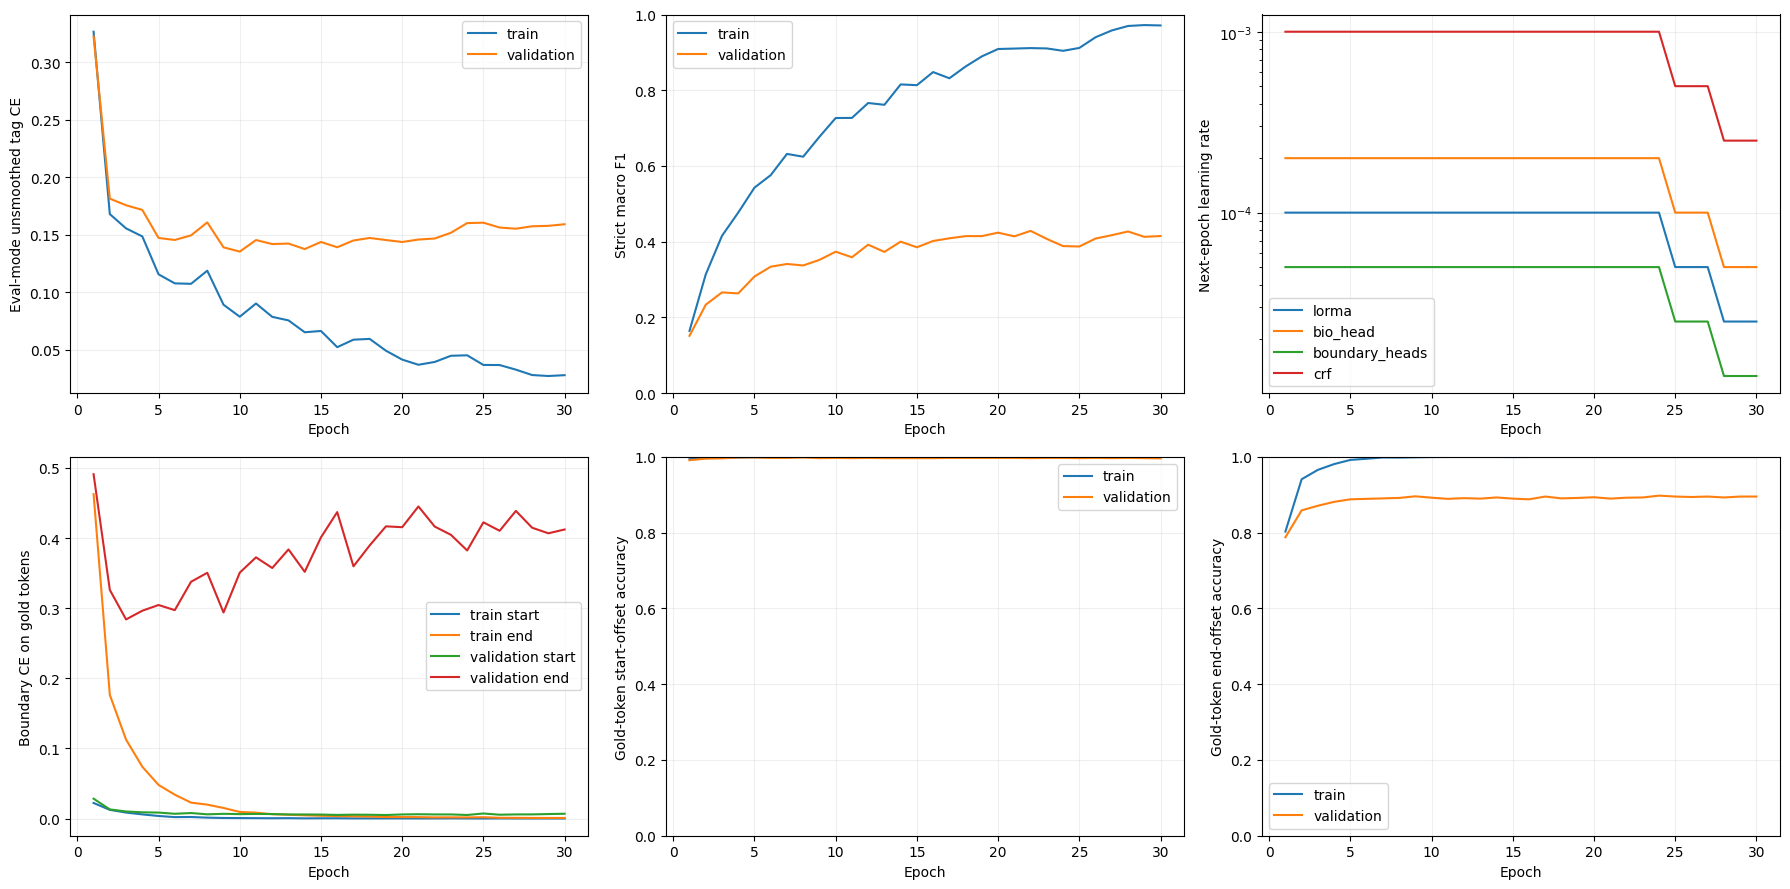

CRF validation NLL per content token: 0.0964428253755689


In [18]:
if "training_state" not in globals() or not training_state["completed"]:
    print("Stage paused; the best checkpoint below is provisional. Save a backup to resume.")
best = torch.load(RUN_DIR / "best_ner.pt", map_location="cpu", weights_only=False)
assert best["protocol"] == protocol
load_trainable_state(base, best["adapter_state"])
best_epoch = best["epoch"]
del best
gc.collect()
val_predictions, val_losses, val_boundary_diagnostics, val_seconds = evaluate(model, documents, texts, val_windows,
    split["validation_ids"], tag_names, SETTINGS["prediction_batch_size"], device,
    True, SETTINGS["decode_mode"], SETTINGS["boundary_loss_weight"],
    SETTINGS["aux_tag_loss_weight"], SETTINGS["trim_span_whitespace"])
val_gold = {did: gold[did] for did in split["validation_ids"]}
best_metrics = official_evaluate(RUN_DIR, val_gold, val_predictions, labels,
    SRC / "evaluate_phase2.py", DATA_DIR / "Train/labels.txt", "best")
best_metrics["losses"] = val_losses
best_metrics["boundary_diagnostics"] = val_boundary_diagnostics
write_json(RUN_DIR / "best_boundary_diagnostics.json", val_boundary_diagnostics)
write_json(RUN_DIR / "best_validation_predictions.json", val_predictions)
write_json(RUN_DIR / "best_validation_metrics.json", best_metrics)
write_json(RUN_DIR / "best_crf_parameters.json", {
    "tag_names": tag_names, "transition_direction": "previous_to_current",
    **{k: v.tolist() for k, v in base.crf.numpy_parameters().items()},
})
summary, errors = span_errors(texts, val_gold, val_predictions)
write_json(RUN_DIR / "validation_error_analysis.json", summary)
write_json(RUN_DIR / "validation_error_samples.json", errors)
print("Run:", RUN_ID)
print("Best epoch:", best_epoch)
print("Strict macro F1:", best_metrics["strict_macro_f1"])
print("Decoder reference:", REFERENCE_DECODER_VALIDATION_F1)
print("Encoder-decoder LoRA+CRF reference:", REFERENCE_ENCDEC_VALIDATION_F1)
print("Evaluation losses:", val_losses)
print("Gold boundary accuracy:", {k: val_boundary_diagnostics[k] for k in ("start_offset_accuracy", "end_offset_accuracy")})
print("Entity-token precision/recall:", val_boundary_diagnostics["bio_tagging"]["entity_token_precision_ignoring_type"], val_boundary_diagnostics["bio_tagging"]["entity_token_recall_ignoring_type"])
for label, row in val_boundary_diagnostics["bio_tagging"]["per_label"].items():
    print(label, "type-token recall", round(row["recall"], 3), "begin-tag recall", row["begin_tag_recall"])
print("Label             Precision     Recall         F1    Gold")
for label, row in best_metrics["per_label"].items():
    print(f"{label:16s} {row['precision']:9.3f} {row['recall']:10.3f} {row['f1']:10.3f} "
          f"{row['true_positive']+row['false_negative']:7d}")
print("Span error analysis:", summary)
for error in errors[:10]:
    print(error["kind"], error["span"], repr(error["entity_text"]))

import matplotlib.pyplot as plt
history = read_json(RUN_DIR / "history.json")
checks = [r for r in history if r.get("kind") == "validation" and r["epoch"] > 0]
fig, panels = plt.subplots(2, 3, figsize=(18, 9))
axes = panels.ravel()
epochs = [r["epoch"] for r in checks]
for name in ("train", "validation"):
    axes[0].plot(epochs, [r[name + "_losses"]["unweighted_tag_loss"] for r in checks], label=name)
axes[0].set(xlabel="Epoch", ylabel="Eval-mode unsmoothed tag CE")
axes[1].plot(epochs, [r["train_strict_macro_f1"] for r in checks], label="train")
axes[1].plot(epochs, [r["strict_macro_f1"] for r in checks], label="validation")
axes[1].set(xlabel="Epoch", ylabel="Strict macro F1", ylim=(0, 1))
for kind in ("lorma", "bio_head", "boundary_heads", "crf"):
    axes[2].plot(epochs, [r["learning_rates_next_epoch"][kind] for r in checks], label=kind)
axes[2].set(xlabel="Epoch", ylabel="Next-epoch learning rate", yscale="log")
for name in ("train", "validation"):
    for side in ("start", "end"):
        axes[3].plot(epochs, [r[name + "_losses"][side + "_loss"] for r in checks],
                     label=name + " " + side)
    for index, side in ((4, "start"), (5, "end")):
        axes[index].plot(epochs, [r[name + "_boundary_diagnostics"][side + "_offset_accuracy"]
                                  for r in checks], label=name)
axes[3].set(xlabel="Epoch", ylabel="Boundary CE on gold tokens")
axes[4].set(xlabel="Epoch", ylabel="Gold-token start-offset accuracy", ylim=(0, 1))
axes[5].set(xlabel="Epoch", ylabel="Gold-token end-offset accuracy", ylim=(0, 1))
for axis in axes:
    axis.legend()
    axis.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(RUN_DIR / "training_curves.png", dpi=160)
plt.show()

print("CRF validation NLL per content token:", val_losses["crf_nll_per_content_token"])


## 8. CodaBench export

`GENERATE_TEST_PREDICTIONS` controls export from the best validation checkpoint. The ZIP
contains one root-level `prediction.json` with original-text offsets for every test ID.


In [19]:
from zipfile import ZipFile, ZIP_DEFLATED
from IPython.display import display, FileLink

if GENERATE_TEST_PREDICTIONS:
    # Submission always uses the saved best, even if the review cell was skipped.
    export_best = torch.load(RUN_DIR / "best_ner.pt", map_location="cpu", weights_only=False)
    assert export_best["protocol"] == protocol
    load_trainable_state(base, export_best["adapter_state"])
    export_epoch = export_best["epoch"]
    del export_best
    test_documents, _, test_audit = prepare_documents(test_texts, {}, tokenizer, labels)
    test_ids = sorted(test_texts)
    test_windows = make_windows(test_documents, test_ids, WINDOW_TOKENS, WINDOW_OVERLAP)
    test_predictions, test_seconds = predict(
        model, test_documents, test_texts, test_windows, test_ids, tag_names,
        SETTINGS["prediction_batch_size"], device, SETTINGS["decode_mode"],
        SETTINGS["trim_span_whitespace"])
    assert set(test_predictions) == set(test_texts)
    from evaluate_phase2 import spans as check_spans
    for did, entities in test_predictions.items():
        check_spans(entities, set(labels), f"prediction[{did}]")
        for a, b, label in entities:
            assert 0 <= a < b <= len(test_texts[did])
        if not test_texts[did]:
            assert entities == []
    prediction_path = RUN_DIR / "prediction.json"
    write_json(prediction_path, test_predictions)
    submission_path = Path("/kaggle/working") / f"{RUN_ID}_submission.zip"
    with ZipFile(submission_path, "w", ZIP_DEFLATED) as archive:
        archive.write(prediction_path, "prediction.json")
    with ZipFile(submission_path) as archive:
        assert archive.namelist() == ["prediction.json"]
        assert set(json.loads(archive.read("prediction.json"))) == set(test_texts)
    write_json(RUN_DIR / "test_prediction_summary.json", {
        "checkpoint_epoch": export_epoch,
        "documents": len(test_predictions), "entities": sum(map(len, test_predictions.values())),
        "seconds": test_seconds, "empty_document_ids": [d for d in test_ids if not test_texts[d]],
    })
    print("Submission:", submission_path)
    display(FileLink(str(submission_path.relative_to(Path("/kaggle/working")))))


Submission: /kaggle/working/prefix_ner_lorma_crf_001_fresh_submission.zip


/kaggle/working/prefix_ner_lorma_crf_001_fresh_submission.zip

## 9. Diagnostic reports

The diagnostic archive contains training history, validation scores, the span-error
analysis and the run protocol.


In [20]:
from zipfile import ZipFile, ZIP_DEFLATED
from IPython.display import FileLink, display

diagnostic_path = Path("/kaggle/working") / f"{RUN_ID}_diagnostics.zip"
with ZipFile(diagnostic_path, "w", ZIP_DEFLATED) as archive:
    for path in sorted(RUN_DIR.rglob("*.json")):
        archive.write(path, arcname=str(path.relative_to(RUN_DIR)))
    plot = RUN_DIR / "training_curves.png"
    if plot.exists():
        archive.write(plot, arcname=plot.name)
print("Diagnostic ZIP:", diagnostic_path)
if (RUN_DIR / "best_validation_metrics.json").exists():
    print("Saved best strict macro F1:", read_json(RUN_DIR / "best_validation_metrics.json")["strict_macro_f1"])
display(FileLink(str(diagnostic_path.relative_to(Path("/kaggle/working")))))


Diagnostic ZIP: /kaggle/working/prefix_ner_lorma_crf_001_fresh_diagnostics.zip
Saved best strict macro F1: 0.42861340865836967


/kaggle/working/prefix_ner_lorma_crf_001_fresh_diagnostics.zip

## 10. Resume backup

The optional backup preserves the NER checkpoint, optimizer state, preparation metadata
and source files. Reattach the original Phase 1 run and tokenizer preparation when
resuming or reconstructing the frozen backbone.


In [21]:
from zipfile import ZipFile, ZIP_STORED
from IPython.display import display, FileLink

if MAKE_RESUME_BACKUP:
    backup_path = Path("/kaggle/working") / f"{RUN_ID}_backup.zip"
    backup_tmp = backup_path.with_suffix(".zip.tmp")
    paths = [p for p in RUN_DIR.rglob("*") if p.is_file()
             and "__pycache__" not in p.parts and "parent_input" not in p.parts and not p.name.endswith(".tmp")]
    required_space = sum(p.stat().st_size for p in paths) + 256*2**20
    if shutil.disk_usage(ROOT).free < required_space:
        raise RuntimeError("Not enough free disk for a backup ZIP. Preserve the run folder as Kaggle output")
    with ZipFile(backup_tmp, "w", ZIP_STORED) as archive:
        for path in paths:
            archive.write(path, Path("runs") / RUN_ID / path.relative_to(RUN_DIR))
        archive.write(PREP_DIR / "tokenizer_state.pkl", "preparation/tokenizer_state.pkl")
        archive.write(PREP_DIR / "cache_manifest.json", "preparation/cache_manifest.json")
    backup_tmp.replace(backup_path)
    print("Resumable backup:", backup_path)
    print("Size:", round(backup_path.stat().st_size/2**30, 2), "GiB")
    display(FileLink(str(backup_path.relative_to(Path("/kaggle/working")))))


Resumable backup: /kaggle/working/prefix_ner_lorma_crf_001_fresh_backup.zip
Size: 0.19 GiB


/kaggle/working/prefix_ner_lorma_crf_001_fresh_backup.zip

## References

- The [official CS781 dataset](https://huggingface.co/datasets/Exploration-Lab/CS-781-Capstone) supplies the Phase 2 L-NER folds. The embedded `evaluate_phase2.py` scores exact start offset, end offset and label matches, then averages F1 across the 12 entity labels.
- Bihany et al. provided the identity-inflated multiplicative adapter formulation. [LoRMA](https://aclanthology.org/2025.findings-acl.527/)
- Lample et al. describe neural sequence tagging with learned transition scores. [Neural Architectures for Named Entity Recognition](https://aclanthology.org/N16-1030/)
